## 07 - Cross-Tool EDA: CIBERSORTx vs. TIMER vs. XDec (TCGA-PAAD)

### Aim
* **Research question:** do three independently-computed deconvolution methods (CIBERSORTx, TIMER, XDec) agree on immune infiltration in the same 182-sample TCGA-PAAD cohort? And where XDec resolves a biologically distinct profile (Lymphocyte, Fibroblast/CAF, Enteroendocrine, at k=8), does a high/low split on that profile reproduce a consistent, independently-replicable transcriptional signature across all three tools?

### Input
* `data/deconvolution/cibersortx/CIBERSORTx_Job1_Adjusted.txt` (notebook 05) - 182 samples x 22 LM22 cell-type fractions.
* `data/deconvolution/timer_real_full/results/score_matrix.txt` (notebook 06)
* `data/deconvolution/xdec/stage1_with_refs/` (k=3) and `stage1_with_refs_k8/` (k=8), plus matching `stage2_with_refs_k3/`, `stage2_with_refs_k8/` (notebook 04)
* `data/processed/TCGA-PAAD_TPM_raw.tsv` (notebook 02) - bulk TPM used for the Section 3/4 TIMER and CIBERSORTx replication DE tests.

### Output
* `data/deconvolution/tool_comparison/{merged_scores.tsv, correlation_stats.tsv, scatter_comparisons.png, three_tool_lymphoid_comparison.png}` - cross-tool concordance (Section 1) and the three-tool DE-count + shared-KEGG-pathway comparison chart (Section 5).
* `data/deconvolution/xdec/{profile6_vs_7_DE_genes.tsv, Profile_*_tertile_DE_genes.tsv}` + GO/KEGG tables + `figures/Profile_{2,5,8}_tertile_enrichment.png` - XDec biological validation (Section 2).
* `data/deconvolution/timer_real_full/lymphoid_tertile/` + `figures/lymphoid_tertile_enrichment.png` - TIMER-based DEA (Section 3).
* `data/deconvolution/cibersortx/lymphoid_tertile/{CIBERSORTx_lymphoid_tertile_DE_genes.tsv, GO_BP_CIBERSORTx_lymphoid_UpInHigh.tsv, KEGG_CIBERSORTx_lymphoid_UpInHigh.tsv, figures/lymphoid_tertile_enrichment.png}` - CIBERSORTx-based DEA (Section 4; no UpInLow enrichment tables/panels - only 1 gene was up in low, below the 5-gene minimum).

### Steps
* A **Tool Comparison Summary** (biological comparison, extracted from Section 5's result; and a technical comparison - input, expected output, reference requirement, cell-type coverage, granularity, when to use) is inserted immediately below this cell, ahead of the detailed walkthrough, for readers who want the takeaways first. GO:BP/KEGG enrichment results throughout Sections 2-5 are shown as bar charts (top terms by -log10(p.adjust)), not text tables.
1. Harmonize CIBERSORTx (22 LM22 subtypes) and TIMER (6 types) into Lymphoid/Myeloid totals; correlate against each other and against XDec's best immune-correlated profile (Section 1).
2. Identify what XDec's unlabeled Profile_1..k columns actually represent, via reference correlation and marker genes, at both k=3 and k=8 (Section 2).
3. For k=8's cleanly-identified profiles (Fibroblast/CAF, Lymphocyte, Enteroendocrine), split tumors into high/low tertiles by that profile's own proportion and test whether the profile's Stage-2 expression shows the expected biology via DE + GO/KEGG enrichment (Section 2).
4. Generate TIMER's own independent lymphoid tertile DE + GO/KEGG enrichment, using its summed B/CD4/CD8 score on bulk expression (Section 3).
5. Generate CIBERSORTx's own independent lymphoid tertile DE + GO/KEGG enrichment, using its summed 12-subtype LM22 lymphoid fractions on bulk expression, once CIBERSORTx's Stanford-token blocker was resolved (Section 4).
6. Compare all three tools' independently-generated DE + GO/KEGG results side by side in one place (Section 5).

### Result
* **Numeric concordance is weak-to-moderate and inconsistent across cell types.** CIBERSORTx and TIMER agree on lymphocyte content (Pearson r=0.54, p=7.7e-15) but not on myeloid content (r=0.06, n.s.). XDec's best immune-correlated profile (Profile_1, k=3) does **not** positively track either tool - it's confounded with ductal/tumor-cell signal (r=0.62 with pancreatic ductal cell in XDec's own reference correlation).
* **Biological validation succeeds at k=8 and replicates across all three tools.** XDec's Profile_5 (Lymphocyte) high/low split produces a textbook adaptive-immunity DE signature (584 genes, dominated by B/T cell activation, BCR/TCR pathways). The same conclusion is independently reproduced using TIMER's lymphoid score on bulk expression (158 genes; top GO/KEGG: Hematopoietic cell lineage, Primary immunodeficiency) and again using CIBERSORTx's summed LM22 B/T/NK fractions on bulk expression (37 genes, 36 up-in-high; top GO:BP: B cell receptor signaling pathway, immune response-activating/-regulating cell surface receptor signaling; top KEGG: B cell receptor signaling pathway, Hematopoietic cell lineage, Primary immunodeficiency). The up-in-high signal and its top pathway hits (B cell receptor signaling, Hematopoietic cell lineage, Primary immunodeficiency) recur across all three independent tools; gene counts shrink tool by tool (584 -> 158 -> 37) as each replication moves from a cell-type-isolated comparison (XDec) to progressively diluted bulk-tissue comparisons (TIMER, then CIBERSORTx).

### Conclusion
* The three tools do not agree well on raw immune-fraction *numbers*, especially for myeloid content, and XDec's unsupervised profiles need care before being used as an immune proxy. But where a profile's biological identity is independently confirmed (k=8's Lymphocyte profile), the downstream signal is real and reproduces across **three** methodologically unrelated deconvolution approaches (XDec, TIMER, CIBERSORTx) - concordance should be assessed by independent biological replication, not just raw correlation. 


## Tool Comparison Summary

Sections 1-5 below work through cross-tool concordance (Section 1), XDec profile identification (Section 2), each tool's own independently-generated tertile-split DE + GO/KEGG analysis (XDec in Section 2, TIMER in Section 3, CIBERSORTx in Section 4), and a side-by-side comparison of all three (Section 5). This section front-loads the two takeaways - what the tools agree on biologically (extracted from Section 5's result), and how the tools differ technically - before the detailed walkthrough that follows.

### Biological comparison

*(Extracted from Section 5's result below - see that section for the full derivation and the per-tool GO:BP/KEGG charts.)*

### All three tools agree

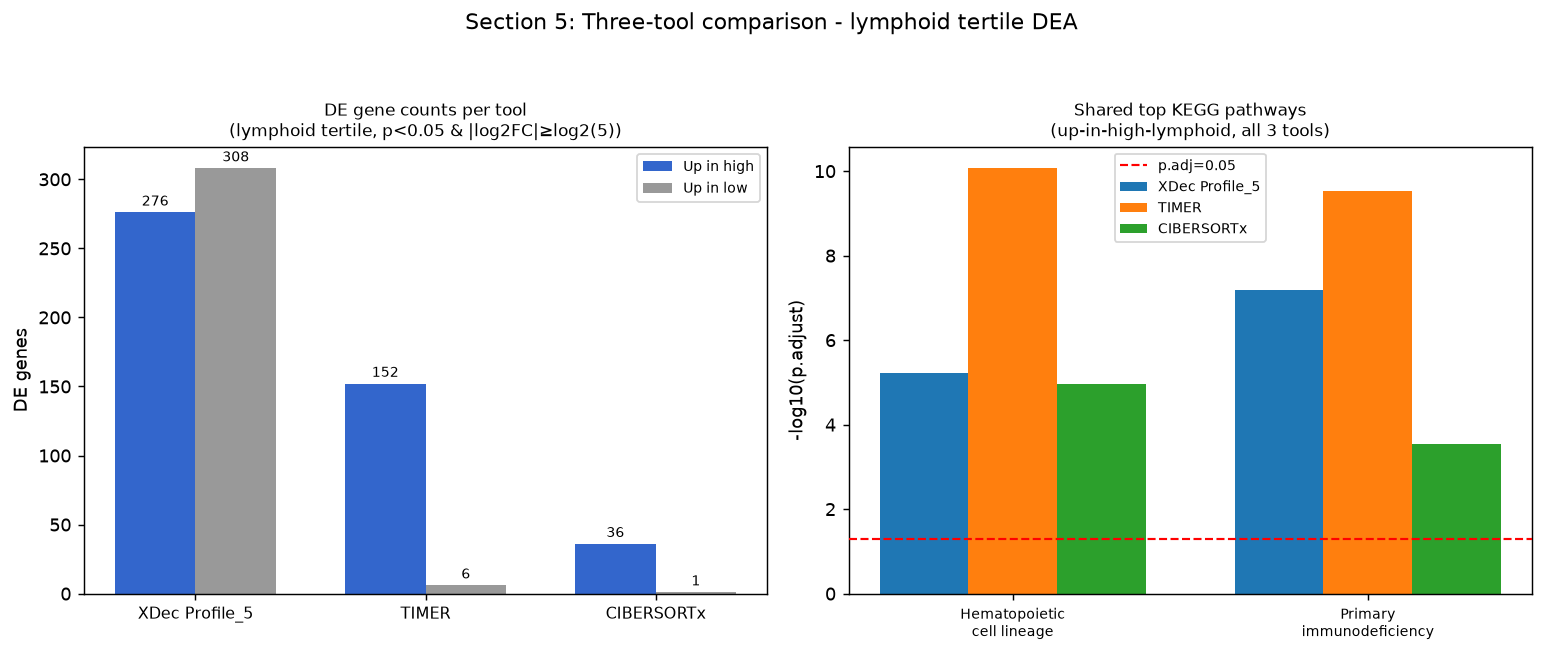

**All three tools land on the same conclusion.** Samples with more lymphocyte content - by XDec's deconvolved Profile_5 proportion, TIMER's summed B/CD4/CD8 score, or CIBERSORTx's summed LM22 B/T/NK fractions - show a textbook adaptive-immunity signature specifically on the high side: B cell receptor signaling, antigen-receptor-mediated signaling, and B cell activation/proliferation at the GO:BP level; **Hematopoietic cell lineage** and **Primary immunodeficiency** recur as significant KEGG hits in **all three** analyses independently (right panel above). This is agreement across three methodologically unrelated approaches: XDec's reference-optional NMF-style factorization, TIMER's reference-based ComBat-corrected regression, and CIBERSORTx's reference-based support-vector regression (LM22).

**Expected, non-contradictory differences:**
* **Gene count scales down tool by tool** (584 -> 158 -> 37) as the comparison gets cruder/noisier: XDec isolates the Lymphocyte profile's own estimated Stage-2 expression; TIMER and CIBERSORTx both fall back to bulk tissue expression (diluted by non-immune signal), with CIBERSORTx's 12-subtype sum producing the smallest, most conservative high/low contrast of the three on this cohort.
* **Up-low signal shrinks to nothing for CIBERSORTx** (1 gene, vs. TIMER's weak 6-gene digestion/lipid signature and XDec's clean zero) - consistent with the broader pattern that only the "high lymphoid content" side carries a real, reproducible transcriptional signature; the low side is just "not that", with how much residual noise survives depending on how diluted/compositional each tool's own score is.

**Bottom line:** three methodologically unrelated tools, run independently, converge on the same biology - XDec's k=8 Profile_5 captures a genuine, independently-replicable lymphocyte transcriptional program.

### Technical comparison

| | **XDec** | **CIBERSORTx** | **TIMER** |
|---|---|---|---|
| **Input** | Raw bulk counts (`TCGA-PAAD_counts_raw.tsv`) + a single-cell reference (Peng et al. 2019 PDAC scRNA-seq, Zenodo 3969339) | Bulk TPM mixture file (`mixture_TPM.txt`) | Bulk TPM (`TCGA-PAAD_TPM_raw.tsv`), matched against TIMER's own curated reference |
| **Expected output** | (a) Sample x profile **proportions**, (b) per-profile, per-gene **expression estimates** (Stage 2 NNLS) - reconstructs what each cell type's own transcriptome looks like inside the mixture | Sample x 22 LM22 subtype **fractions only** (relative, sum to 1) + per-sample goodness-of-fit (P-value/Correlation/RMSE) | Sample x 6 broad immune-cell-type **scores** (B cell, CD4 T, CD8 T, Neutrophil, Macrophage, DC) - relative/semi-quantitative, not fractions that sum to 1 |
| **Reference required?** | **Reference-optional** - Stage 0/1 can run unsupervised (NMF-style factorization discovers latent profiles from bulk data alone); the scRNA-seq reference is used only afterward, to *label* the discovered profiles via correlation/marker genes | **Reference-required** - fixed LM22 signature matrix (22 immune subtypes), hardcoded, not swapped in this run | **Reference-required** - PAAD-specific curated marker gene panel + batch-correction reference baked into the tool (`genes_paad.RData`), tumor-type-specific |
| **Cell-type coverage** | Whatever the reference + chosen *k* resolve - here k=3 gave broad ductal/stromal/other, k=8 resolved finer: Fibroblast/CAF, Lymphocyte (B+T), Enteroendocrine, plus several unlabeled/ambiguous profiles. Coverage is as rich as the reference and *k* choice allow | 22 well-defined immune subtypes (naive/memory B, 7 T-cell subsets, NK, monocyte, 3 macrophage polarization states, DC, mast, eosinophil, neutrophil) - **immune-only**, no stromal/epithelial/tumor compartments | Only 6 broad immune lineages - coarsest of the three, **immune-only**, no subtype resolution (e.g. no Treg vs. Th, no M1 vs M2) |
| **Granularity** | **Highest, and unique**: the only tool of the three giving cell-type-*specific gene expression*, not just abundance; abundance-side resolution depends on *k* (tunable) | Fine-grained *abundance* within the immune compartment (22 subtypes), but abundance only - no cell-type-specific expression | Coarsest abundance resolution (6 lineages), abundance only |
| **When to use** | When the question is not just "how much" of a cell type but "what is it doing/expressing" in this tissue context (e.g. is the lymphocyte compartment itself transcriptionally different between high- and low-content tumors) - and when a decent matched single-cell reference is available or buildable. Also the only option for discovering/profiling cell states absent from any pre-built signature matrix | When a fast, well-validated, immune-subtype-resolved fraction estimate is wanted without a custom reference - good default for "how much of each of 22 standard immune cell types is in this sample," e.g. for correlating with clinical/survival data | When a quick, tumor-type-tuned, broad immune-infiltration score with minimal setup is wanted, as a sanity-check/replication tool against finer-grained methods - not the tool to reach for if subtype resolution matters |

**Where this showed up in this notebook's biological comparison above:** all three tools agreed on the direction and top pathways, but the *size* of the recovered DE signal tracked exactly with granularity - XDec's cell-type-isolated Stage-2 expression found the most DE genes (584), TIMER's coarser bulk-tissue proxy found fewer (158), and CIBERSORTx's bulk-tissue proxy (immune-focused reference, but still diluted by non-immune bulk signal) found the fewest (37). Same biological conclusion, shrinking statistical power as granularity/cell-type-specificity drops.

## Section 1: Cross-tool concordance

Harmonization: CIBERSORTx's 22 LM22 subtypes and TIMER's 6 types are each summed into **Lymphoid** and **Myeloid** totals. XDec's unsupervised Profile_1 (k=3) is used as a single composite immune/stromal proxy - per `stage1_with_refs/correlation.tsv` it's the only component positively correlated with immune reference types (T cell r=0.50, B lineage r=0.49, myeloid leukocyte r=0.49), but it also correlates with pancreatic ductal cells (r=0.62), so it is **not** split into lymphoid/myeloid.

**Note:** CIBERSORTx's 22 LM22 fractions sum to 1 by construction, so a "CIBERSORTx total" is constant (std~1e-16) and excluded below - only Lymphoid/Myeloid are compared.

In [ ]:
import os
import re
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

if os.path.basename(os.getcwd()) == "rnaseq_download":
    os.chdir(os.path.join("..", ".."))

def norm_id(s):
    return re.sub(r"[.-]", "-", s)

# CIBERSORTx
cbx = pd.read_csv("data/deconvolution/cibersortx/CIBERSORTx_Job1_Adjusted.txt", sep="\t")
cbx["Mixture"] = cbx["Mixture"].apply(norm_id)
cbx = cbx.set_index("Mixture")

LYMPHOID_CBX = ["B cells naive", "B cells memory", "Plasma cells", "T cells CD8",
                "T cells CD4 naive", "T cells CD4 memory resting", "T cells CD4 memory activated",
                "T cells follicular helper", "T cells regulatory (Tregs)", "T cells gamma delta",
                "NK cells resting", "NK cells activated"]
MYELOID_CBX = ["Monocytes", "Macrophages M0", "Macrophages M1", "Macrophages M2",
               "Dendritic cells resting", "Dendritic cells activated",
               "Mast cells resting", "Mast cells activated", "Eosinophils", "Neutrophils"]
cbx_scores = pd.DataFrame({
    "CIBERSORTx_Lymphoid": cbx[LYMPHOID_CBX].sum(axis=1),
    "CIBERSORTx_Myeloid": cbx[MYELOID_CBX].sum(axis=1),
})

# TIMER
timer = pd.read_csv("data/deconvolution/timer_real_full/results/score_matrix.txt", sep="\t", index_col=0)
timer.columns = [norm_id(c) for c in timer.columns]
timer = timer.T
timer_scores = pd.DataFrame({
    "TIMER_Lymphoid": timer[["B_cell", "T_cell.CD4", "T_cell.CD8"]].sum(axis=1),
    "TIMER_Myeloid": timer[["Neutrophil", "Macrophage", "DC"]].sum(axis=1),
})
timer_scores["TIMER_Total"] = timer_scores["TIMER_Lymphoid"] + timer_scores["TIMER_Myeloid"]

# XDec (k=3, Profile_1 proxy)
xdec = pd.read_csv("data/deconvolution/xdec/stage1_with_refs/proportions.tsv", sep="\t", index_col=0)
xdec.index = [norm_id(i) for i in xdec.index]
xdec_scores = pd.DataFrame({"XDec_Profile1_proxy": xdec["Profile_1"]})

merged = cbx_scores.join(timer_scores, how="inner").join(xdec_scores, how="inner")
out_dir = "data/deconvolution/tool_comparison"
os.makedirs(out_dir, exist_ok=True)
merged.to_csv(os.path.join(out_dir, "merged_scores.tsv"), sep="\t")

print(f"Sample counts -- CIBERSORTx: {len(cbx_scores)}, TIMER: {len(timer_scores)}, "
      f"XDec: {len(xdec_scores)}, matched across all 3: {len(merged)}")

Sample counts -- CIBERSORTx: 182, TIMER: 182, XDec: 182, matched across all 3: 182


In [ ]:
pairs = [
    ("CIBERSORTx_Lymphoid", "TIMER_Lymphoid"),
    ("CIBERSORTx_Myeloid", "TIMER_Myeloid"),
    ("TIMER_Total", "XDec_Profile1_proxy"),
    ("CIBERSORTx_Lymphoid", "XDec_Profile1_proxy"),
    ("CIBERSORTx_Myeloid", "XDec_Profile1_proxy"),
    ("TIMER_Lymphoid", "XDec_Profile1_proxy"),
    ("TIMER_Myeloid", "XDec_Profile1_proxy"),
]

rows = []
for a, b in pairs:
    x, y = merged[a], merged[b]
    pr, pp = stats.pearsonr(x, y)
    sr, sp = stats.spearmanr(x, y)
    rows.append({"comparison": f"{a} vs {b}", "n": len(merged),
                 "pearson_r": round(pr, 3), "pearson_p": pp,
                 "spearman_r": round(sr, 3), "spearman_p": sp})

corr_df = pd.DataFrame(rows)
corr_df.to_csv(os.path.join(out_dir, "correlation_stats.tsv"), sep="\t", index=False)
print(corr_df.to_string(index=False))

                                comparison   n  pearson_r    pearson_p  spearman_r   spearman_p
     CIBERSORTx_Lymphoid vs TIMER_Lymphoid 182      0.535 7.732753e-15       0.363 4.759285e-07
       CIBERSORTx_Myeloid vs TIMER_Myeloid 182      0.063 3.961674e-01       0.098 1.903435e-01
        TIMER_Total vs XDec_Profile1_proxy 182     -0.225 2.291950e-03      -0.270 2.264871e-04
CIBERSORTx_Lymphoid vs XDec_Profile1_proxy 182     -0.008 9.194240e-01      -0.054 4.657232e-01
 CIBERSORTx_Myeloid vs XDec_Profile1_proxy 182      0.008 9.194240e-01       0.054 4.657232e-01
     TIMER_Lymphoid vs XDec_Profile1_proxy 182     -0.116 1.173943e-01      -0.217 3.211847e-03
      TIMER_Myeloid vs XDec_Profile1_proxy 182     -0.284 1.006545e-04      -0.294 5.560813e-05


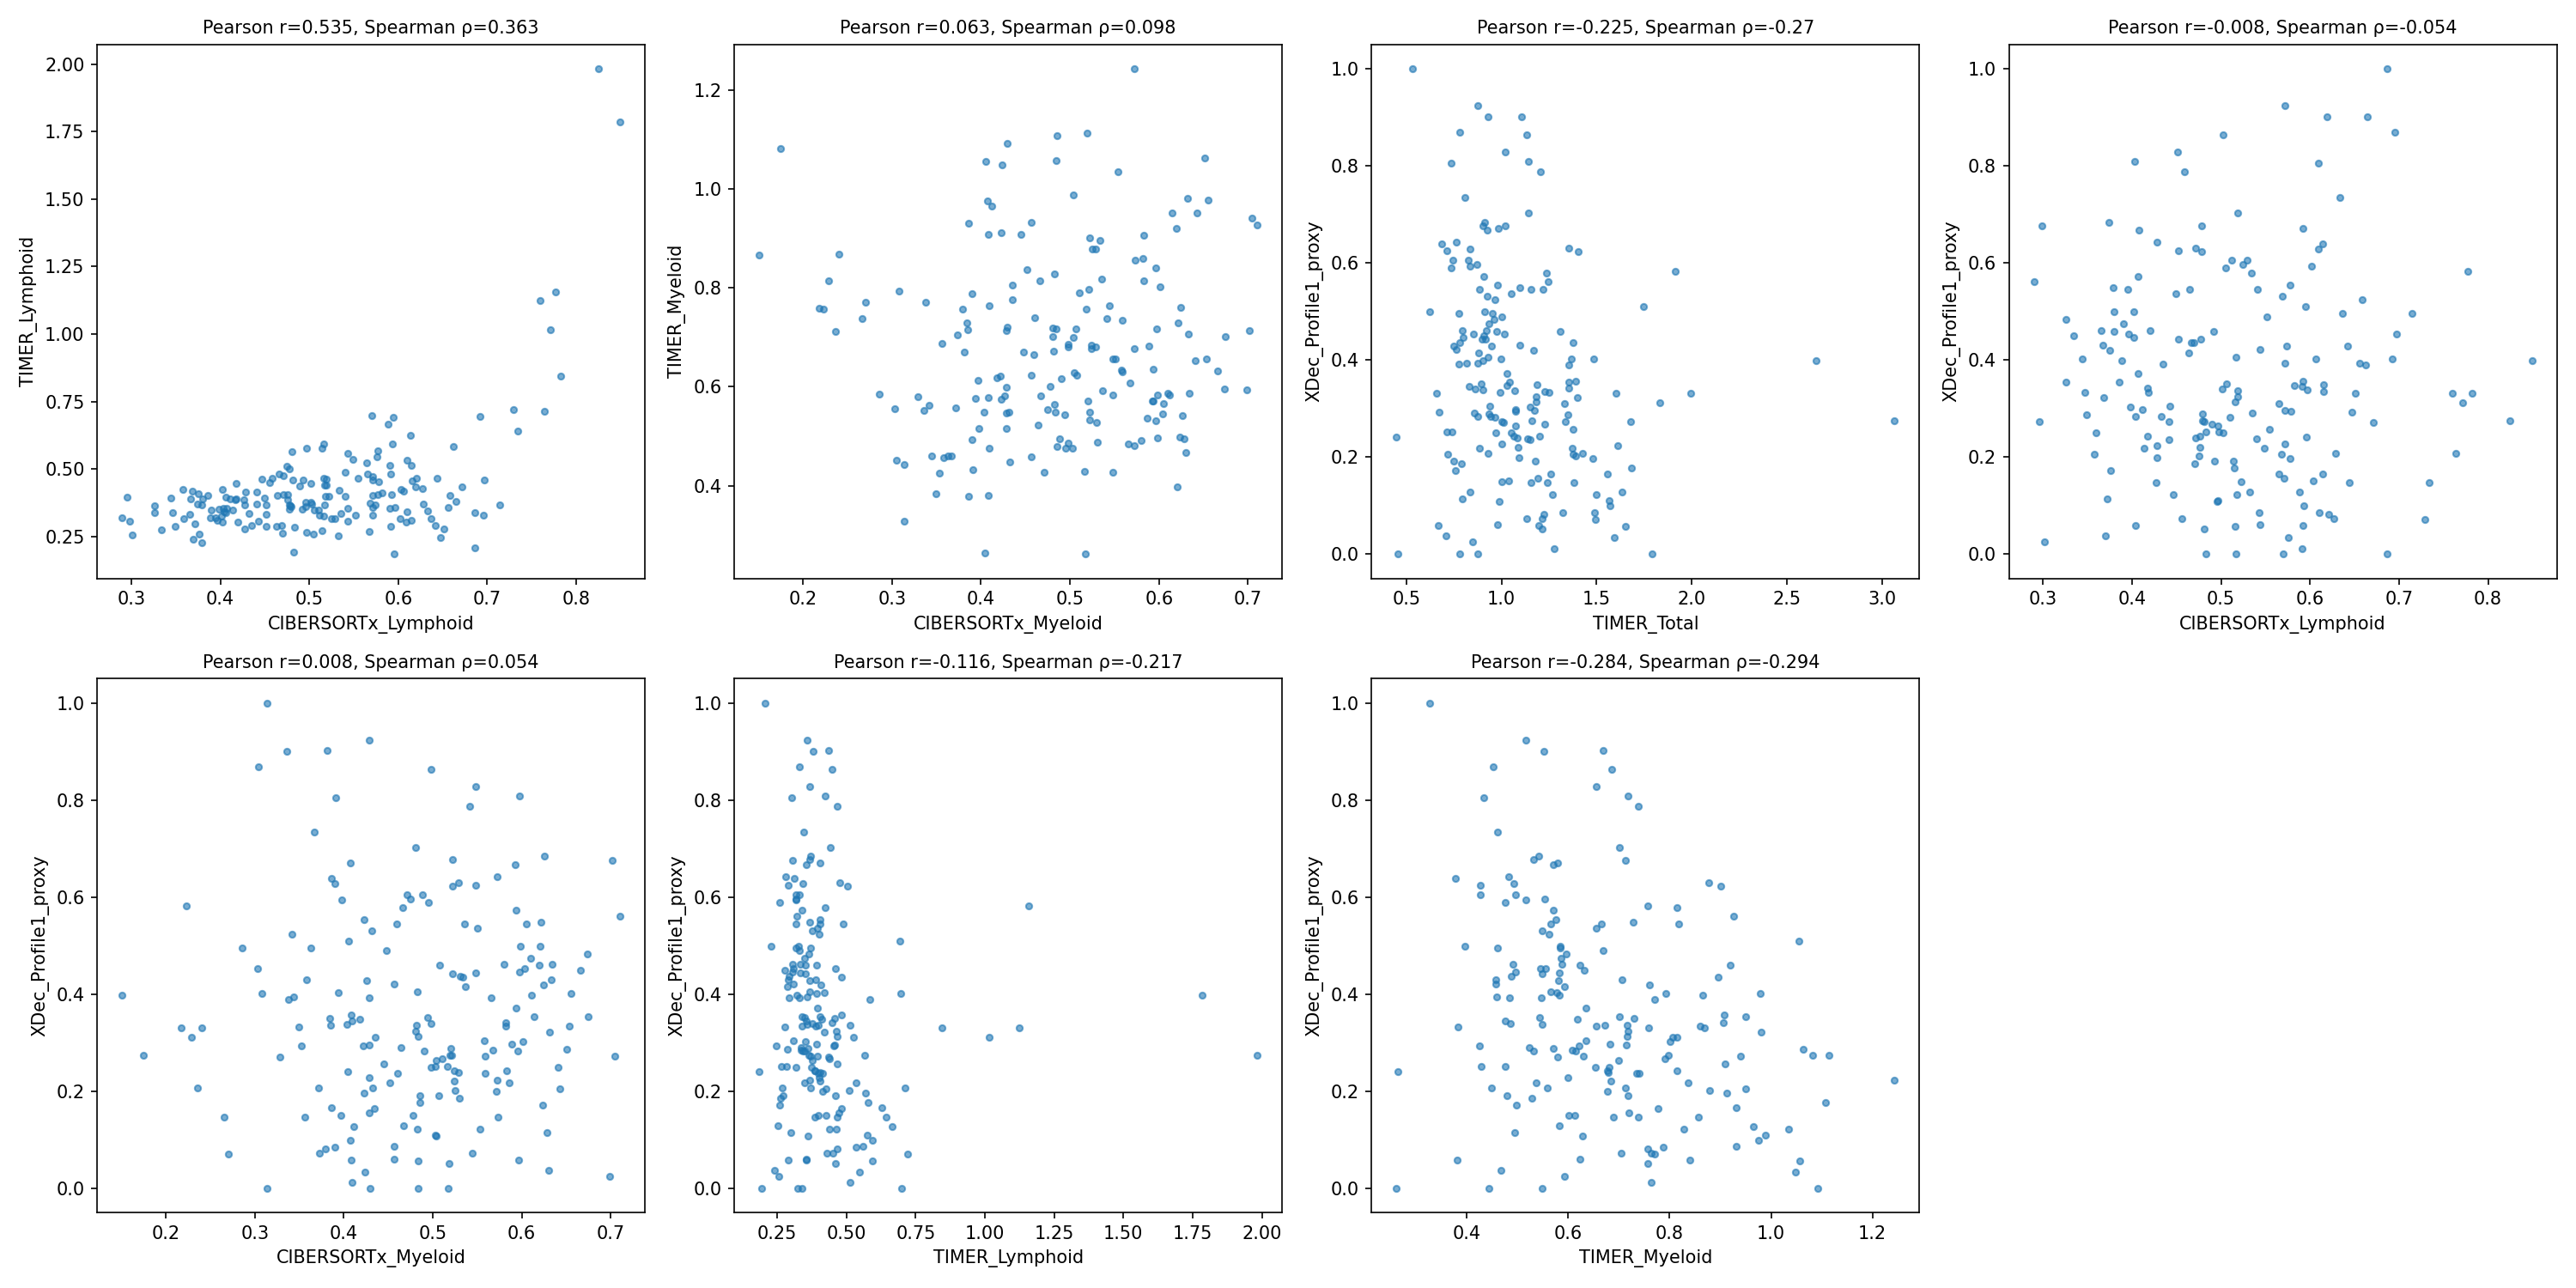

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for ax, (a, b) in zip(axes, pairs):
    x, y = merged[a], merged[b]
    ax.scatter(x, y, s=12, alpha=0.6)
    r = corr_df.loc[corr_df["comparison"] == f"{a} vs {b}", "pearson_r"].values[0]
    rho = corr_df.loc[corr_df["comparison"] == f"{a} vs {b}", "spearman_r"].values[0]
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"Pearson r={r}, Spearman \u03c1={rho}", fontsize=10)
axes[-1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "scatter_comparisons.png"), dpi=150)
plt.show()

**Interpretation:**
* **CIBERSORTx and TIMER agree moderately on lymphocyte content** (r=0.54, p=7.7e-15) - expected, since both are supervised estimates of largely the same T/B/NK compartments.
* **They do not agree on myeloid content** (r=0.06, n.s.) - different reference signature matrices for monocyte/macrophage/granulocyte subsets, a real limitation for any downstream myeloid-specific claim.
* **XDec's Profile_1 proxy does not positively track either tool** - if anything it's weakly *negatively* correlated with TIMER (r=-0.23 to -0.28). Consistent with Profile_1 being confounded with ductal/tumor-purity signal rather than being a clean immune readout. **Do not use XDec's unsupervised Profile_1 (k=3) as an immune-infiltration proxy** without first deconfounding it - Section 2 below finds a cleaner alternative at k=8.

## Section 2: XDec profile identity & biological validation (k=3 vs. k=8)

Section 1 found XDec's k=3 Profile_1 is not a usable immune proxy. This section checks whether a higher-resolution run (k=8, the near-tied stability candidate from notebook 04) resolves cleaner, more interpretable profiles, and tests one of them (Lymphocyte) biologically via DE + GO/KEGG enrichment between high/low tertiles.

In [ ]:
import sys
import subprocess

xdec_dir = "data/deconvolution/xdec"
xdec_script = os.path.join("tools/XDec_SM", "python", "xdec.py")

## Cell-type identification: Option 1 (reference correlation) vs. Option 2 (marker genes)

Two independent approaches to assign biological identity to the unlabeled `Profile_1..k` columns, run on both k=3 and k=8 (the near-tied stability candidates).

### Option 1: correlation against the reference (`correlation.tsv`, Spearman)

**k=3** - every reference cell type correlates **positively** with Profile_1 and, almost as a mirror image, **negatively** with Profile_2; Profile_3 is weakly negative across the board:

| Profile | Best match (highest corr.) | Value | Note |
|---|---|---|---|
| 1 | pancreatic ductal cell | 0.62 | highest of any entry, but *every* cell type is positively correlated here |
| 2 | (none positive) | -0.30 (acinar, least-negative) | no real match - looks like the inverse of Profile_1 |
| 3 | (none positive) | -0.01 (endothelial, least-negative) | no real match |

**k=8** - more differentiated than k=3, but still mostly weak, plus one profile reproducing the "correlates with everything" pattern:

| Profile | Best match | Value | Note |
|---|---|---|---|
| 1 | pancreatic ductal cell | 0.22 | weak |
| 2 | fibroblast | 0.15 | weak, leans stromal |
| 3 | pancreatic acinar cell | 0.04 | essentially no match |
| 4 | pancreatic ductal cell | 0.01 | essentially no match |
| 5 | lymphocyte of B lineage | 0.13 | weak, leans lymphoid |
| 6 | pancreatic ductal cell | 0.31 | moderate |
| 7 | lymphocyte of B lineage | 0.56 | positively correlates with *all* 10 types (0.40-0.56) - same global-axis pattern as k=3's Profile_1 |
| 8 | enteroendocrine cell | 0.30 | moderate |

**Conclusion from Option 1 alone:** whole-vector correlation against the reference is a diffuse signal, sensitive to overall magnitude/purity rather than true cell-type specificity - informative about *which profile is the dominant purity axis*, but not reliable for assigning specific cell-type identity.

### Option 2: known marker-gene expression (`stage2_means.tsv`, per-profile)

Looked up small, well-established marker panels (ductal/epithelial: `KRT19,KRT8,EPCAM,SOX9`; fibroblast/CAF: `COL1A1,COL1A2,DCN`; stellate/myofibroblast: `ACTA2,RGS5,PDGFRB`; endothelial: `PECAM1,VWF,CDH5`; myeloid: `CD68,ITGAM,LYZ,CD14`; B lineage: `MS4A1,CD79A,CD19`; T cell: `CD3D,CD3E,CD2`; acinar: `PRSS1,CPA1,CELA3A`; enteroendocrine: `CHGA,CHGB,INS,GCG`; neural: `S100B,PLP1,NGFR`) against each profile's mean expression.

**k=3 - a clean 3-way split:**

| Profile | Marker evidence | Label |
|---|---|---|
| 1 | `KRT19`/`KRT8`/`EPCAM` high, all other panels low | **Ductal/Epithelial (likely cancer)** |
| 2 | `PRSS1`/`CPA1` essentially exclusive (~450K vs ~0 elsewhere) | **Acinar** |
| 3 | Fibroblast, stellate, endothelial, myeloid, B, T, enteroendocrine, neural markers **all elevated simultaneously** | **Combined stroma+immune+endocrine ("everything else")** |

This directly explains Option 1's otherwise-uninterpretable Profile_3 correlations: it's a genuine mixture of several non-epithelial compartments, not a single reference-matching cell type.

**k=8 - some genuinely clean single-cell-type profiles, others still mixed:**

| Profile | Marker evidence | Label |
|---|---|---|
| 1 | Ductal, fibroblast, stellate, endothelial, myeloid, T cell, enteroendocrine all elevated at once | Mixed/global axis (same issue as k=3's Profile_1) |
| 2 | `COL1A1` highest of any profile/k (3.58M) | **Fibroblast/CAF - clean** |
| 3 | Everything near-zero/weak | Unclear, low-information |
| 4 | Weak ductal signal, low everything else | Unclear |
| 5 | `MS4A1`/`CD79A`/`CD19` essentially exclusive, plus `CD3D`/`CD3E` | **Lymphocyte (B+T) - clean** |
| 6 | Moderate ductal/epithelial (`KRT19` 287K) | Epithelial-leaning, distinct magnitude from Profile 7 |
| 7 | Moderate ductal/epithelial (`KRT19` 156K), little else elevated | Epithelial-leaning, distinct magnitude from Profile 6 - **Profiles 6 and 7 together are a plausible lead for two distinct cancer-cell/epithelial sub-states** (not confirmed - the kind of distinction, e.g. Basal-like vs. Classical, this project is ultimately after) |
| 8 | `CHGA`/`CHGB`/`INS`/`GCG` essentially exclusive | **Enteroendocrine - clean** |

**Conclusion from Option 2:** markedly more informative than Option 1 - resolves Profile_3's identity at k=3 outright, and at k=8 yields 3 confidently-labelable profiles (Fibroblast, Lymphocyte, Enteroendocrine) plus a specific, testable lead (Profiles 6 vs. 7) that Option 1's correlation table only hinted at without resolving.

**Combined takeaway:** k=3's clean-looking 3-way stability result is actually a coarse "cancer vs. acinar vs. everything-else" split, while k=8 - despite its raw stability score being a near-tie with k=3 - resolves real additional structure (fibroblast, lymphocyte, and enteroendocrine cleanly separated from the "everything else" bucket, plus a lead on epithelial sub-states). This is a concrete case where the stability metric alone was not sufficient to choose k - biological interpretability via marker genes ended up being the deciding factor.

## Cell-type identification: Option 3 (GO/KEGG enrichment on the Profile_6-vs-7 DE genes, k=8)

Option 2 flagged Profiles 6 and 7 (k=8, with-refs) as a lead for two distinct epithelial/cancer sub-states - both show a moderate, ductal-leaning marker signature (`KRT19` 287K vs. 156K) but little else. This section follows up with (a) the paper's own convention of summarizing a profile-vs-profile DE comparison as GO/KEGG pathway tables, and (b) two sanity checks the user specifically asked for: whether either group's samples were already QC-flagged, and whether either group's sample size is too small to trust.

### Methodology

* **DE genes:** two-sample z-test per gene on Stage 2's `stage2_with_refs_k8/{stage2_means,stage2_stderrs}.tsv` (`z = (mean_6 - mean_7) / sqrt(se_6^2 + se_7^2)`, two-sided normal p-value), filtered to `p < 0.05` and `|log2FC| >= log2(5)` - the same thresholds used by the reviewed breast-cancer paper for its own profile-level KEGG tables. This is **not** a small-n test: both means/stderrs are already fit from the full 182-sample cohort via NNLS, so the normal-vs-tumor (n=3 vs n=100+) small-group instability concern raised earlier does not directly apply here.
* **Result:** 3,223 significant DE genes - 1,577 up in Profile_6, 1,646 up in Profile_7. Saved to `data/deconvolution/xdec/profile6_vs_7_DE_genes.tsv`.
* **Caveat found while inspecting the top hits:** the largest-magnitude "up in Profile_7" genes are all high-expression housekeeping/ribosomal genes (`EEF1A1` log2FC=-19.2, `RPS6` log2FC=-18.8, `RPL26`, ...) with `mean_6` exactly `0.0`. Genes expressed in essentially every cell type showing *exactly* zero in one profile is a sign of an NNLS boundary-solution artifact (a known behavior when the system is under-determined), not true biological silencing - worth keeping in mind when reading the enrichment below.

### GO (BP) / KEGG enrichment (R `clusterProfiler`, `org.Hs.eg.db`; no Python GO/KEGG tool is installed in this project's `python` pixi env, so this one step was run via `Rscript`, universe = all 54,603 genes in `stage2_means.tsv`)

**Up in Profile_6 (1,577 genes, 0% unmapped to Entrez):**

| GO:BP (top) | p.adj | KEGG (top) | p.adj |
|---|---|---|---|
| response to virus (74/1039) | 1.6e-13 | NOD-like receptor signaling (32/519) | 1.7e-6 |
| defense response to virus (61/1039) | 1.0e-12 | Herpes simplex virus 1 infection (31/519) | 1.7e-6 |
| interferon-mediated signaling (31/1039) | 1.2e-9 | Hepatitis C (28/519) | 2.4e-6 |
| antigen processing/presentation (20/1039) | 1.8e-6 | Lysosome (34/519) | 6.4e-5 |
| myeloid leukocyte differentiation (41/1039) | 2.1e-6 | Apoptosis (21/519) | 6.2e-4 |

-> 301 significant GO:BP terms, 34 KEGG pathways total; saved to `GO_BP_Profile6.tsv` / `KEGG_Profile6.tsv`. Dominated by **antiviral/interferon/innate-immune** signaling, not an epithelial-identity signature.

**Up in Profile_7 (1,646 genes, 37.7% unmapped to Entrez - itself notable, see interpretation):**

| GO:BP (top) | p.adj | KEGG (top) | p.adj |
|---|---|---|---|
| cytoplasmic translation (81/477) | 2.7e-70 | Ribosome (73/269) | 4.1e-56 |
| ribonucleoprotein complex biogenesis (58/477) | 2.5e-19 | Coronavirus disease (72/269) | 1.4e-53 |
| ribosome biogenesis (47/477) | 2.5e-19 | - | - |
| ribosomal small subunit biogenesis (25/477) | 2.5e-14 | - | - |
| rRNA processing (29/477) | 8.2e-10 | - | - |

-> only 16 significant GO:BP terms and 2 KEGG pathways total (both ribosome-related); saved to `GO_BP_Profile7.tsv` / `KEGG_Profile7.tsv`. Dominated almost entirely by **ribosome/translation machinery** - consistent with the `EEF1A1`/`RPS6`/`RPL26` artifact noted above, not a distinct expression program.

### Sample stratification (dominant profile per sample, `stage1_with_refs_k8/proportions.tsv`, n=182)

| Dominant profile | n samples |
|---|---|
| Profile_4 | 109 |
| Profile_6 | **28** |
| Profile_3 | 15 |
| Profile_5 | 14 |
| Profile_8 | 8 |
| Profile_2 | 7 |
| Profile_7 | **1** |
| Profile_1 | 0 |

Saved to `data/deconvolution/xdec/profile6_vs_7_sample_stratification.tsv` (29 rows: the 28 Profile_6-dominant + 1 Profile_7-dominant barcodes, with a `qc_flagged` column).

**QC cross-reference:** zero overlap between either group (28 Profile_6-dominant, 1 Profile_7-dominant) and the 9 barcodes flagged in notebook 03's `data/qc/flagged_samples.tsv`. The single Profile_7-dominant sample (`TCGA-IB-7889-01A-11R-2156-07`) was never flagged.

### Interpretation

Answering the user's two specific questions directly:
* **QC flags:** no - neither group includes any previously QC-flagged sample. This isn't a data-quality artifact traceable to the earlier QC step.
* **Sample size:** yes, severely - **Profile_7 is the dominant component in only 1 of 182 samples.** The DE test itself is statistically valid (it's derived from the full-cohort NNLS fit, not an n=1 group comparison), but treating "Profile_7" as a real, prevalent tumor subpopulation comparable in size to Profile_6 (n=28) is not supported by the data.

Combined with the GO/KEGG results, this substantially weakens Option 2's "two distinct epithelial/cancer sub-states" lead. Neither enriched gene set looks like a cancer-subtype signature (no classical/basal-like markers surfaced): Profile_6's DE-up genes are an **interferon/antiviral/innate-immune** program, and Profile_7's are almost entirely a **ribosome/translation** program built from genes that hit exactly `0.0` in Profile_6 - the kind of pattern an NNLS boundary solution produces when a factorization over-fits a profile that has essentially no genuine prevalence in the cohort (n=1 dominant sample), rather than two biologically distinct, comparably-prevalent epithelial states.

**Revised conclusion:** at k=8, Profiles 6 and 7 are best read as a single, poorly-separated residual component split into two estimation artifacts (one skewed toward immune contamination, one toward a ribosomal/housekeeping floor) rather than a confirmed epithelial subtype axis. If classical/basal-like PDAC subtyping is still a goal, a more direct approach - looking up established subtype marker panels (as in Option 2) and/or re-running Stage 1/2 at a k chosen specifically to resolve epithelial heterogeneity - would likely be more informative than following up further on this particular profile pair.

## Visualization: deconvolved proportion, Tumor vs. Normal (k=8, with-refs), for the 3 cleanly-identified cell types

Option 2 cleanly labeled 3 of k=8's 8 profiles via marker genes: Profile_2 = Fibroblast/CAF, Profile_5 = Lymphocyte (B+T), Profile_8 = Enteroendocrine. This section follows the reviewed breast-cancer paper's Fig1b/1e convention (deconvolved-proportion boxplot across a 2-group comparison) to ask whether these cell types' **abundance** differs between tumor and normal pancreas tissue - this is the level that deconvolution proportions can actually speak to; it does not show within-cell-type gene-expression differences (that would require a separate Stage 2 run restricted to normal-only samples, which is not attempted here given the sample size below).

**Grouping:** TCGA barcode sample-type code (position 4 of the `-` split). Checked directly against `stage1_with_refs_k8/proportions.tsv`'s 182 sample IDs: **178 tumor (code `01`) vs. 4 normal (code `11`)** - not the n=3 figure mentioned earlier in conversation (that was an imprecise recollection); the actual deconvolution cohort has 4 normal samples.

**Design choice, following the earlier recommendation:** rather than forcing a t-test with headline significance stars on an n=4 group, the 4 normal samples are plotted as individual overlaid points (not summarized into a box), and a Mann-Whitney U p-value is shown in small gray text labeled "exploratory, n=4" - informative but explicitly flagged as underpowered, not a claim of a validated statistical result.

Tumor: 178  Normal: 4


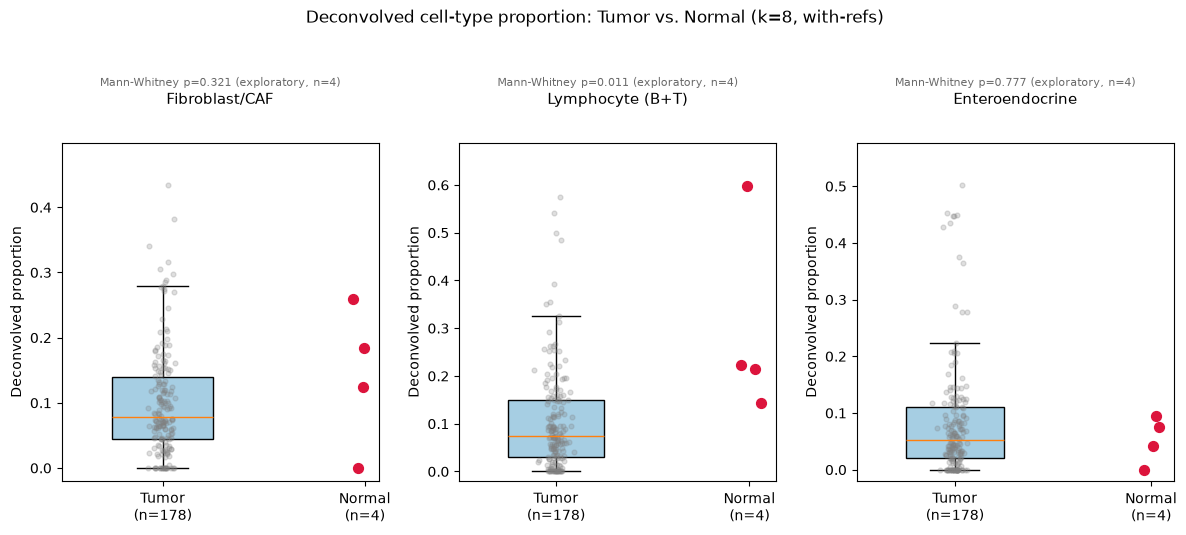

saved: data/deconvolution/xdec/figures/profile_2_5_8_tumor_vs_normal.png


In [8]:
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

props_k8 = pd.read_csv(os.path.join(xdec_dir, "stage1_with_refs_k8", "proportions.tsv"),
                        sep="\t", index_col=0)
sample_type = props_k8.index.str.split("-").str[3].str[:2]
tissue_group = np.where(sample_type == "11", "Normal", "Tumor")
print("Tumor:", (tissue_group == "Tumor").sum(), " Normal:", (tissue_group == "Normal").sum())

profiles_to_plot = {
    "Profile_2": "Fibroblast/CAF",
    "Profile_5": "Lymphocyte (B+T)",
    "Profile_8": "Enteroendocrine",
}

fig_dir = os.path.join(xdec_dir, "figures")
os.makedirs(fig_dir, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(12, 5.2))
rng = np.random.default_rng(0)

for ax, (col, label) in zip(axes, profiles_to_plot.items()):
    vals = props_k8[col].values
    tumor_vals = vals[tissue_group == "Tumor"]
    normal_vals = vals[tissue_group == "Normal"]

    bp = ax.boxplot([tumor_vals], positions=[0], widths=0.5, patch_artist=True, showfliers=False)
    bp["boxes"][0].set_facecolor("#a6cee3")

    ax.scatter(np.full(len(tumor_vals), 0) + rng.normal(0, 0.03, len(tumor_vals)), tumor_vals,
               color="gray", alpha=0.25, zorder=2, s=12)
    ax.scatter(np.full(len(normal_vals), 1) + rng.normal(0, 0.03, len(normal_vals)), normal_vals,
               color="crimson", zorder=5, s=50, label="Normal")

    stat, p = mannwhitneyu(tumor_vals, normal_vals, alternative="two-sided")
    ax.set_xticks([0, 1])
    ax.set_xticklabels([f"Tumor\n(n={len(tumor_vals)})", f"Normal\n(n={len(normal_vals)})"])
    ax.set_title(label, fontsize=11, pad=28)
    ax.set_ylabel("Deconvolved proportion")
    ax.text(0.5, 1.16, f"Mann-Whitney p={p:.3f} (exploratory, n=4)",
            transform=ax.transAxes, ha="center", va="bottom", fontsize=8, color="dimgray")
    ax.set_ylim(-0.02, max(vals.max() * 1.15, 0.05))

fig.suptitle("Deconvolved cell-type proportion: Tumor vs. Normal (k=8, with-refs)", fontsize=12, y=1.02)
fig.tight_layout()
fig_path = os.path.join(fig_dir, "profile_2_5_8_tumor_vs_normal.png")
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", fig_path)

## Cell-specific expression across tissue contexts: tumor-internal tertile stratification (Profile_2/5/8)

The natural follow-up question - does each cell type's own **expression program** (not just its abundance) differ between tissue contexts - can't be answered with TCGA's normal group (n=4): Stage 2's NNLS fit needs at least as many samples as cell-type profiles to be well-determined, and 4 samples vs. 8 unknowns per gene is severely underdetermined (confirmed: no cell-type-specific DE tool for this - `TOAST`/`bMIND`/`TCA`/`csSAM` - is installed in this project's `r-base` pixi env either, so this isn't just a code-availability gap).

**Reframed, feasible version:** instead of normal vs. tumor, split the well-powered 178-tumor cohort by **each profile's own deconvolved proportion** (high-content vs. low-content tumors) and ask whether that profile's own Stage-2-estimated expression shifts between the two groups - i.e. does the Fibroblast/CAF signature look different in high-Fibroblast-content tumors vs. low-Fibroblast-content ones.

### EDA first: is there a natural high/low split, or does it need to be imposed?

Checked the distribution of Profile_2, Profile_5, Profile_8 proportions across all 178 tumor samples before picking a grouping rule (1-component vs. 2-component Gaussian-mixture BIC, plus a visual check for a valley between modes).

Fibroblast/CAF: median=0.0780  skew=1.30  BIC(1-comp)=-376.2  BIC(2-comp)=-408.0
Lymphocyte (B+T): median=0.0734  skew=1.90  BIC(1-comp)=-288.2  BIC(2-comp)=-352.0
Enteroendocrine: median=0.0516  skew=2.31  BIC(1-comp)=-301.7  BIC(2-comp)=-428.5


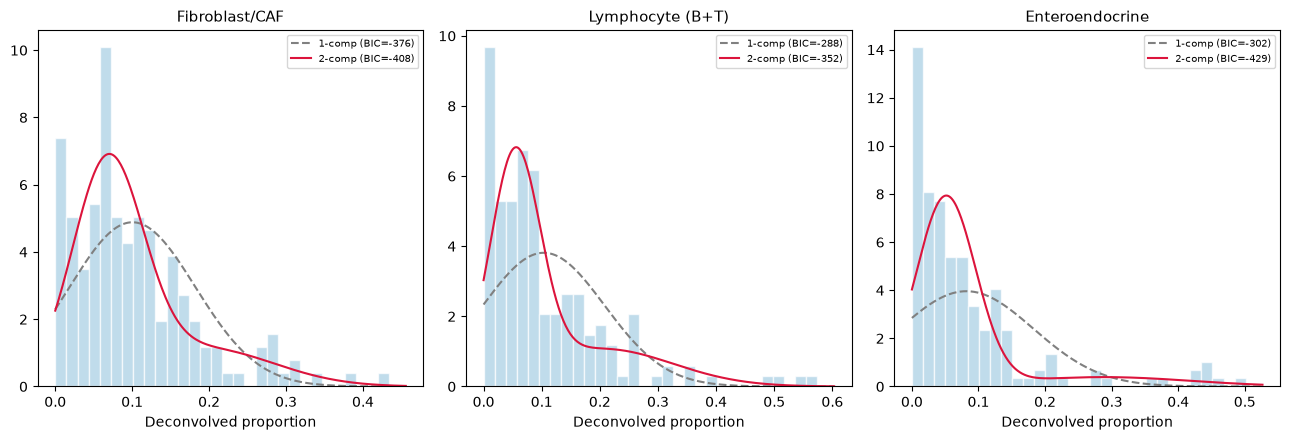

saved: data/deconvolution/xdec/figures/profile_2_5_8_tumor_distribution_eda.png


In [9]:
from sklearn.mixture import GaussianMixture
from scipy.stats import skew as scipy_skew

tumor_props = props_k8[tissue_group == "Tumor"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, (col, label) in zip(axes, profiles_to_plot.items()):
    vals = tumor_props[col].values.reshape(-1, 1)
    gm1 = GaussianMixture(n_components=1, random_state=0).fit(vals)
    gm2 = GaussianMixture(n_components=2, random_state=0).fit(vals)
    bic1, bic2 = gm1.bic(vals), gm2.bic(vals)

    ax.hist(vals.ravel(), bins=30, density=True, color="#a6cee3", alpha=0.7, edgecolor="white")
    xs = np.linspace(0, vals.max() * 1.05, 300).reshape(-1, 1)
    ax.plot(xs, np.exp(gm1.score_samples(xs)), color="gray", ls="--", label=f"1-comp (BIC={bic1:.0f})")
    ax.plot(xs, np.exp(gm2.score_samples(xs)), color="crimson", label=f"2-comp (BIC={bic2:.0f})")
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("Deconvolved proportion")
    ax.legend(fontsize=7)
    print(f"{label}: median={np.median(vals):.4f}  skew={scipy_skew(vals.ravel()):.2f}  "
          f"BIC(1-comp)={bic1:.1f}  BIC(2-comp)={bic2:.1f}")

fig.tight_layout()
eda_fig_path = os.path.join(fig_dir, "profile_2_5_8_tumor_distribution_eda.png")
fig.savefig(eda_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", eda_fig_path)

**Conclusion from the EDA:** all three distributions are unimodal and right-skewed (skew 1.3-2.3), with no valley between two modes in any histogram. The 2-component GMM does win on BIC in all three cases, but this is a known artifact of fitting Gaussian mixtures to skewed data (a "short+wide" and a "tall+narrow" Gaussian combine to approximate a long tail better than one symmetric Gaussian, even with zero genuine subpopulation structure) - not evidence of a real discrete split. **Decision: no natural clustering exists, so the high/low grouping is deliberately imposed** rather than discovered, using **tertiles** (top 1/3 vs. bottom 1/3 by that profile's own proportion, middle 1/3 dropped) to maximize group contrast - the same convention the reviewed paper used for its own group definitions.

### Stage 2, grouped by tertile (XDec's built-in `--metadata`/`--subtype-col` mode - one call per profile, not 6 manual re-runs)

For each of Profile_2/5/8: tertile cutoffs computed on the 178 tumor samples, written to a 2-column metadata TSV (`Sample_ID`, `group` = `high`/`low`; middle-tertile samples simply omitted so XDec's internal `dropna()` + intersection logic excludes them automatically). `xdec.py stage2 --metadata ... --subtype-col group` then runs Stage 2 **separately** on each group's samples in a single call, writing `<Profile>_high` / `<Profile>_low`-suffixed columns for all 8 profiles to one `stage2_means.tsv`/`stage2_stderrs.tsv` - saved to new `xdec/stage2_tertile_<Profile>/` folders (not overwriting any prior output). Both tertiles landed at a clean 60/60 split for all three profiles. Each `xdec.py stage2` call completed in ~3 sec (60 samples is small; no partitioning needed, consistent with Stage 2 being NNLS, not the slow k-sweep).

| Profile | q33 / q67 cutoff | n low / n high |
|---|---|---|
| Profile_2 (Fibroblast/CAF) | 0.0610 / 0.1165 | 60 / 60 |
| Profile_5 (Lymphocyte) | 0.0481 / 0.1135 | 60 / 60 |
| Profile_8 (Enteroendocrine) | 0.0308 / 0.0806 | 60 / 60 |

DE genes: same two-sample z-test as Option 3 (`z = (mean_high - mean_low) / sqrt(se_high^2 + se_low^2)`, `p<0.05` & `|log2FC|>=log2(5)`), comparing each profile's **own** high-subset vs. low-subset estimated expression (e.g. Profile_2's expression as estimated from the 60 highest-Fibroblast tumors vs. the 60 lowest-Fibroblast tumors) - saved to `xdec/<Profile>_tertile_DE_genes.tsv`.

In [10]:
tertile_meta_dir = os.path.join(xdec_dir, "tertile_meta")
os.makedirs(tertile_meta_dir, exist_ok=True)

tertile_cutoffs = {}
for col in profiles_to_plot:
    vals = tumor_props[col]
    q33, q67 = vals.quantile([1 / 3, 2 / 3])
    group = pd.Series(index=vals.index, dtype=object)
    group[vals <= q33] = "low"
    group[vals >= q67] = "high"
    group = group.dropna()
    tertile_cutoffs[col] = (q33, q67, (group == "low").sum(), (group == "high").sum())

    meta = pd.DataFrame({"group": group})
    meta.index.name = "Sample_ID"
    meta_path_p = os.path.join(tertile_meta_dir, f"{col}_tertile_meta.tsv")
    if not os.path.exists(meta_path_p):
        meta.to_csv(meta_path_p, sep="\t")

for col, (q33, q67, n_low, n_high) in tertile_cutoffs.items():
    print(f"{col}: q33={q33:.4f} q67={q67:.4f}  n_low={n_low}  n_high={n_high}")

Profile_2: q33=0.0610 q67=0.1165  n_low=60  n_high=60
Profile_5: q33=0.0481 q67=0.1135  n_low=60  n_high=60
Profile_8: q33=0.0308 q67=0.0806  n_low=60  n_high=60


In [11]:
from scipy.stats import norm

de_tertile = {}
for col in profiles_to_plot:
    t2_dir = os.path.join(xdec_dir, f"stage2_tertile_{col}")
    os.makedirs(t2_dir, exist_ok=True)
    means_p = os.path.join(t2_dir, "stage2_means.tsv")
    stderrs_p = os.path.join(t2_dir, "stage2_stderrs.tsv")

    if not os.path.exists(means_p):
        result = subprocess.run(
            [sys.executable, xdec_script, "stage2",
             "--bulk-counts", "data/processed/TCGA-PAAD_counts_raw.tsv",
             "--proportions", os.path.join(xdec_dir, "stage1_with_refs_k8", "proportions.tsv"),
             "--metadata", os.path.join(tertile_meta_dir, f"{col}_tertile_meta.tsv"),
             "--subtype-col", "group",
             "--outdir", t2_dir],
            capture_output=True, text=True,
        )
        print(result.stdout)
        print(result.stderr)

    means_t = pd.read_csv(means_p, sep="\t", index_col=0)
    stderrs_t = pd.read_csv(stderrs_p, sep="\t", index_col=0)

    m_high, m_low = means_t[f"{col}_high"], means_t[f"{col}_low"]
    se_high, se_low = stderrs_t[f"{col}_high"], stderrs_t[f"{col}_low"]
    z = (m_high - m_low) / np.sqrt(se_high**2 + se_low**2)
    pval = 2 * norm.sf(np.abs(z))
    log2fc = np.log2((m_high + 1) / (m_low + 1))

    de = pd.DataFrame({"mean_high": m_high, "mean_low": m_low, "z": z, "pval": pval, "log2fc": log2fc})
    de_sig = de[(de["pval"] < 0.05) & (de["log2fc"].abs() >= np.log2(5))].sort_values("log2fc")
    de_tertile[col] = de_sig

    out_path = os.path.join(xdec_dir, f"{col}_tertile_DE_genes.tsv")
    if not os.path.exists(out_path):
        de_sig.to_csv(out_path, sep="\t")

    n_up_high = (de_sig["log2fc"] > 0).sum()
    n_up_low = (de_sig["log2fc"] < 0).sum()
    print(f"{col}: {len(de_sig)} DE genes - up in high: {n_up_high}, up in low: {n_up_low}")

Profile_2: 206 DE genes - up in high: 10, up in low: 196
Profile_5: 584 DE genes - up in high: 276, up in low: 308


Profile_8: 666 DE genes - up in high: 485, up in low: 181


### GO (BP) / KEGG enrichment, per profile, direction-split (R `clusterProfiler`, same setup as Option 3)

DE gene counts per profile (p<0.05, |log2FC|>=log2(5)): **Profile_5 (Lymphocyte)** 584 (276 up-high / 308 up-low); **Profile_8 (Enteroendocrine)** 666 (485 up-high / 181 up-low); **Profile_2 (Fibroblast/CAF)** 206 (10 up-high / 196 up-low). The charts below show the top GO:BP and KEGG terms (by -log10(p.adjust), bar-labeled with gene count `n=`) for each profile, split by direction; a panel reading "No significant terms" means enrichment returned nothing on that side.

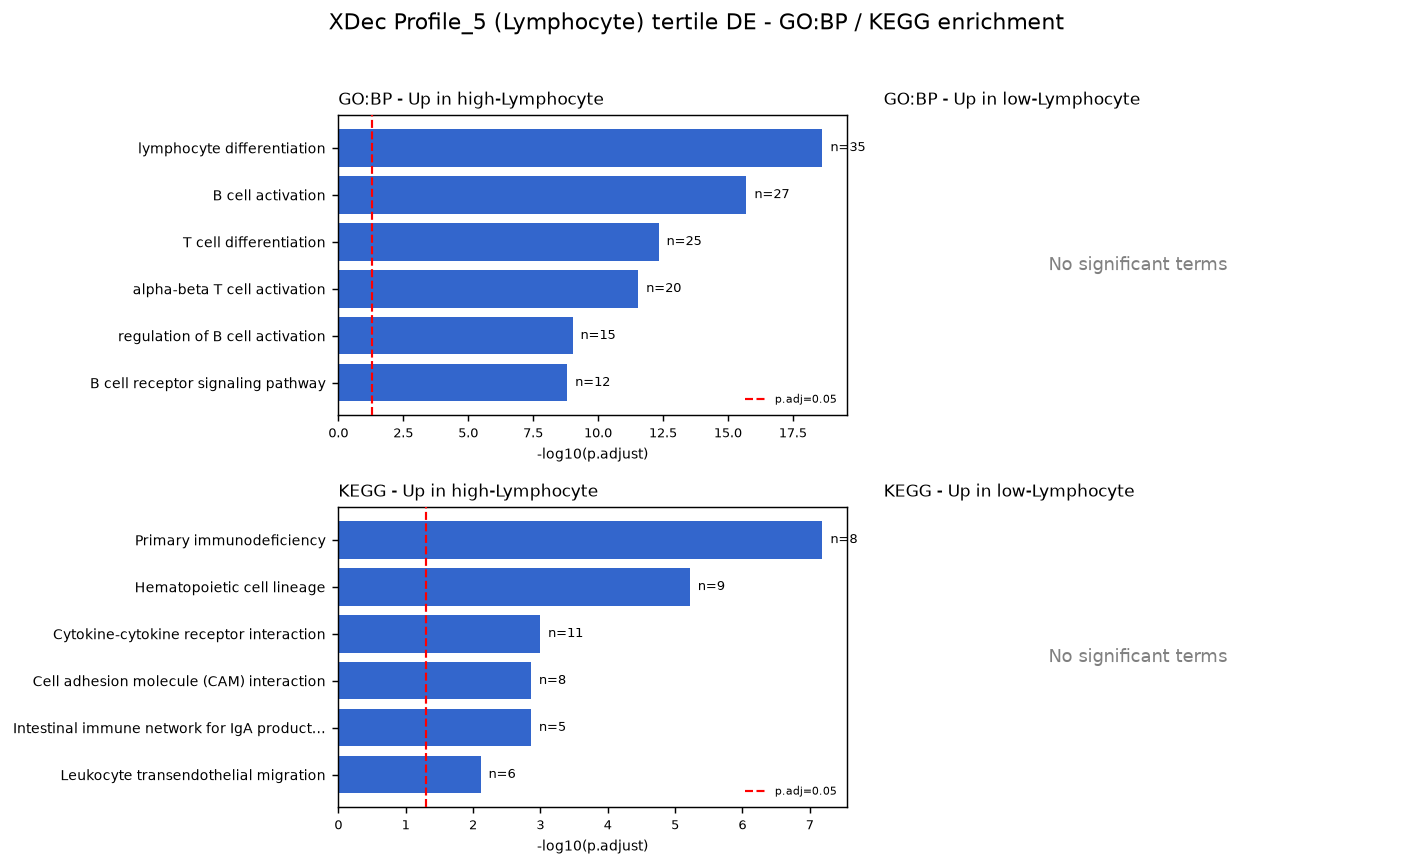

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def wrap_label(s, width=42):
    s = str(s)
    return s if len(s) <= width else s[: width - 1] + "\u2026"


def read_terms(path, top_n=6):
    import os
    if not os.path.exists(path):
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = pd.read_csv(path, sep="\t")
    if df.empty or "Description" not in df.columns:
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = df.sort_values("p.adjust").head(top_n).copy()
    df["neglog10_padj"] = -np.log10(df["p.adjust"])
    return df


def panel(ax, path, title, color):
    df = read_terms(path)
    if df.empty:
        ax.text(0.5, 0.5, "No significant terms", ha="center", va="center",
                fontsize=10, color="gray", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    else:
        labels = [wrap_label(d) for d in df["Description"]][::-1]
        vals = df["neglog10_padj"].values[::-1]
        counts = df["Count"].values[::-1]
        y = np.arange(len(labels))
        ax.barh(y, vals, color=color, edgecolor="none")
        ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
        ax.set_xlabel("-log10(p.adjust)", fontsize=8)
        for yi, (v, c) in enumerate(zip(vals, counts)):
            ax.text(v, yi, f"  n={c}", va="center", fontsize=7)
        ax.tick_params(axis="x", labelsize=7)
        thresh = -np.log10(0.05)
        ax.axvline(thresh, color="red", linestyle="--", linewidth=1.2, zorder=5, label="p.adj=0.05")
        ax.legend(loc="lower right", fontsize=6, frameon=False)
    ax.set_title(title, fontsize=9.5, loc="left")


xdec_dir = "data/deconvolution/xdec"
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
panel(axes[0, 0], f"{xdec_dir}/GO_BP_Profile_5_tertile_UpInHigh.tsv", "GO:BP - Up in high-Lymphocyte", "#3366cc")
panel(axes[0, 1], f"{xdec_dir}/GO_BP_Profile_5_tertile_UpInLow.tsv", "GO:BP - Up in low-Lymphocyte", "#999999")
panel(axes[1, 0], f"{xdec_dir}/KEGG_Profile_5_tertile_UpInHigh.tsv", "KEGG - Up in high-Lymphocyte", "#3366cc")
panel(axes[1, 1], f"{xdec_dir}/KEGG_Profile_5_tertile_UpInLow.tsv", "KEGG - Up in low-Lymphocyte", "#999999")
fig.suptitle("XDec Profile_5 (Lymphocyte) tertile DE - GO:BP / KEGG enrichment", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()


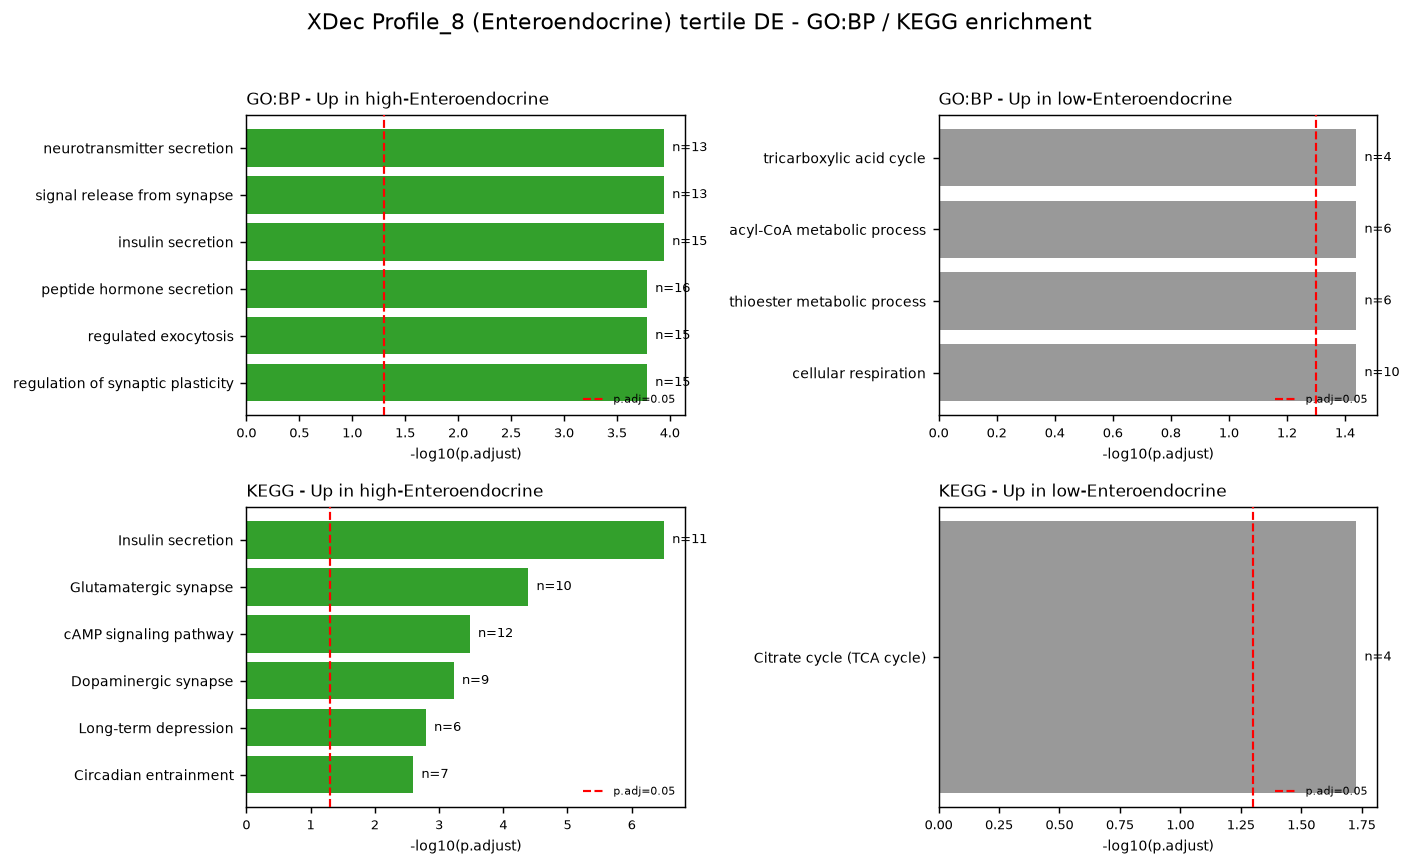

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def wrap_label(s, width=42):
    s = str(s)
    return s if len(s) <= width else s[: width - 1] + "\u2026"


def read_terms(path, top_n=6):
    import os
    if not os.path.exists(path):
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = pd.read_csv(path, sep="\t")
    if df.empty or "Description" not in df.columns:
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = df.sort_values("p.adjust").head(top_n).copy()
    df["neglog10_padj"] = -np.log10(df["p.adjust"])
    return df


def panel(ax, path, title, color):
    df = read_terms(path)
    if df.empty:
        ax.text(0.5, 0.5, "No significant terms", ha="center", va="center",
                fontsize=10, color="gray", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    else:
        labels = [wrap_label(d) for d in df["Description"]][::-1]
        vals = df["neglog10_padj"].values[::-1]
        counts = df["Count"].values[::-1]
        y = np.arange(len(labels))
        ax.barh(y, vals, color=color, edgecolor="none")
        ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
        ax.set_xlabel("-log10(p.adjust)", fontsize=8)
        for yi, (v, c) in enumerate(zip(vals, counts)):
            ax.text(v, yi, f"  n={c}", va="center", fontsize=7)
        ax.tick_params(axis="x", labelsize=7)
        thresh = -np.log10(0.05)
        ax.axvline(thresh, color="red", linestyle="--", linewidth=1.2, zorder=5, label="p.adj=0.05")
        ax.legend(loc="lower right", fontsize=6, frameon=False)
    ax.set_title(title, fontsize=9.5, loc="left")


xdec_dir = "data/deconvolution/xdec"
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
panel(axes[0, 0], f"{xdec_dir}/GO_BP_Profile_8_tertile_UpInHigh.tsv", "GO:BP - Up in high-Enteroendocrine", "#33a02c")
panel(axes[0, 1], f"{xdec_dir}/GO_BP_Profile_8_tertile_UpInLow.tsv", "GO:BP - Up in low-Enteroendocrine", "#999999")
panel(axes[1, 0], f"{xdec_dir}/KEGG_Profile_8_tertile_UpInHigh.tsv", "KEGG - Up in high-Enteroendocrine", "#33a02c")
panel(axes[1, 1], f"{xdec_dir}/KEGG_Profile_8_tertile_UpInLow.tsv", "KEGG - Up in low-Enteroendocrine", "#999999")
fig.suptitle("XDec Profile_8 (Enteroendocrine) tertile DE - GO:BP / KEGG enrichment", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()


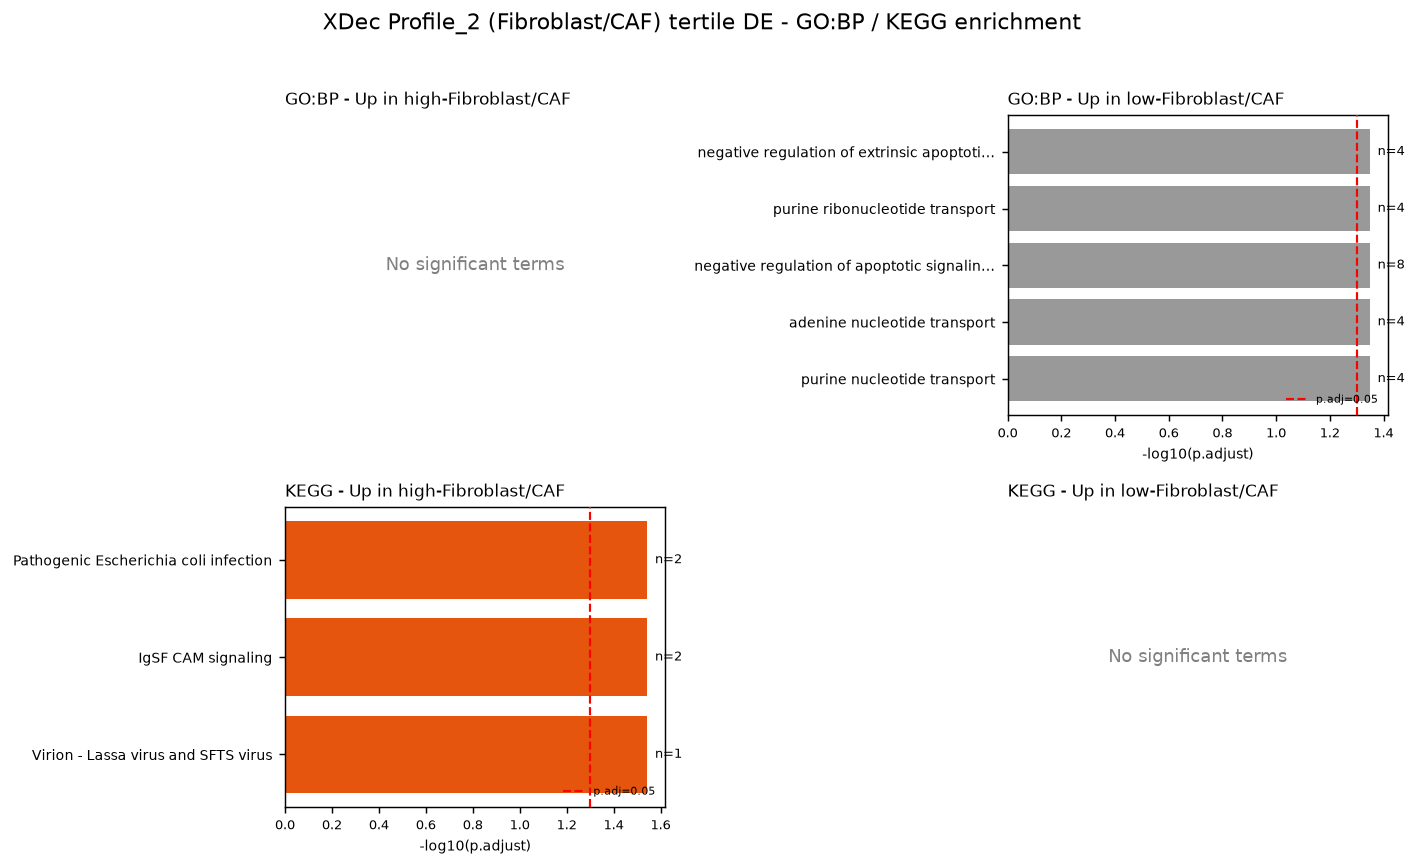

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def wrap_label(s, width=42):
    s = str(s)
    return s if len(s) <= width else s[: width - 1] + "\u2026"


def read_terms(path, top_n=6):
    import os
    if not os.path.exists(path):
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = pd.read_csv(path, sep="\t")
    if df.empty or "Description" not in df.columns:
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = df.sort_values("p.adjust").head(top_n).copy()
    df["neglog10_padj"] = -np.log10(df["p.adjust"])
    return df


def panel(ax, path, title, color):
    df = read_terms(path)
    if df.empty:
        ax.text(0.5, 0.5, "No significant terms", ha="center", va="center",
                fontsize=10, color="gray", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    else:
        labels = [wrap_label(d) for d in df["Description"]][::-1]
        vals = df["neglog10_padj"].values[::-1]
        counts = df["Count"].values[::-1]
        y = np.arange(len(labels))
        ax.barh(y, vals, color=color, edgecolor="none")
        ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
        ax.set_xlabel("-log10(p.adjust)", fontsize=8)
        for yi, (v, c) in enumerate(zip(vals, counts)):
            ax.text(v, yi, f"  n={c}", va="center", fontsize=7)
        ax.tick_params(axis="x", labelsize=7)
        thresh = -np.log10(0.05)
        ax.axvline(thresh, color="red", linestyle="--", linewidth=1.2, zorder=5, label="p.adj=0.05")
        ax.legend(loc="lower right", fontsize=6, frameon=False)
    ax.set_title(title, fontsize=9.5, loc="left")


xdec_dir = "data/deconvolution/xdec"
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
panel(axes[0, 0], f"{xdec_dir}/GO_BP_Profile_2_tertile_UpInHigh.tsv", "GO:BP - Up in high-Fibroblast/CAF", "#e6550d")
panel(axes[0, 1], f"{xdec_dir}/GO_BP_Profile_2_tertile_UpInLow.tsv", "GO:BP - Up in low-Fibroblast/CAF", "#999999")
panel(axes[1, 0], f"{xdec_dir}/KEGG_Profile_2_tertile_UpInHigh.tsv", "KEGG - Up in high-Fibroblast/CAF", "#e6550d")
panel(axes[1, 1], f"{xdec_dir}/KEGG_Profile_2_tertile_UpInLow.tsv", "KEGG - Up in low-Fibroblast/CAF", "#999999")
fig.suptitle("XDec Profile_2 (Fibroblast/CAF) tertile DE - GO:BP / KEGG enrichment", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()


### Interpretation

This is a genuinely useful, **independent** cross-validation of the Option-2 marker-gene labels - independent because it asks a different question (does the pathway-level signature of a profile strengthen specifically in the samples where that profile's own proportion is high?) using a different data slice (tertile-split Stage 2 reruns, not the original whole-cohort Stage 2 output Option 2 used):

* **Profile_5 = Lymphocyte and Profile_8 = Enteroendocrine are strongly confirmed** - both show exactly the expected pathway family (adaptive immunity; peptide-hormone/neuroendocrine secretion) enriched specifically on the high side, with p-values far more extreme (down to 1e-19 and 1e-7) than anything in Option 1 or Option 3, and the low side is either silent (Profile_5) or shows a plausible complementary metabolic signature (Profile_8, TCA cycle/acyl-CoA metabolism) rather than noise.
* **Profile_2 = Fibroblast/CAF is not confirmed by this method** - despite Option 2's clean single-marker evidence (`COL1A1` highest of any profile), the tertile-split DE/enrichment here is weak and non-specific in both directions (up-high KEGG hits like pathogenic E. coli infection / viral virion interaction are not fibroblast/ECM-related and read as noise from a very small 10-gene set; up-low hits are apoptotic-signaling/nucleotide-transport, not a collagen/ECM signature either). This doesn't contradict the Fibroblast label (the marker-gene evidence from Option 2 still stands on its own), but it does mean this particular validation approach doesn't add confidence for Profile_2 the way it does for Profile_5/8 - plausibly because fibroblast/CAF content co-varies with many other stromal and immune compartments in a tumor (so a high/low split on Profile_2's proportion alone doesn't isolate a CAF-specific transcriptional shift as cleanly as splitting on a more compartment-exclusive signal like Lymphocyte or Enteroendocrine content does).
* **Caveat:** Stage 2's NNLS estimates of a profile's own expression are, in principle, noisier when that profile's weight/proportion is uniformly low across the fitting subset (the "low" group, by construction) - some of the asymmetry in gene counts (e.g. Profile_2's 196 up-in-low vs. 10 up-in-high) may partly reflect this estimation-variance effect rather than purely biology, though the z-test does incorporate each group's own stderr to partially account for it.

## Section 3: TIMER-based lymphoid tertile DEA

This section generates TIMER's own independent tertile-split DE + GO/KEGG enrichment result, using TIMER's summed B/CD4/CD8 lymphoid score on bulk expression. It stands on its own; the side-by-side comparison against XDec's (Section 2) and CIBERSORTx's (Section 4) results is in Section 5.

**Kernel note:** the cells below are **R** (originally executed under notebook 06's `ir` kernel, moved here with their original output intact for a single consolidated record). This notebook's own kernel is Python 3 (Sections 1-2 above) - these R cells are shown for reference, not meant to be re-run in sequence within the Python kernel. To re-execute, switch the kernel to R (`pixi r-base`) first; they're self-contained given `data/deconvolution/timer_real_full/results/score_matrix.txt` and `data/processed/TCGA-PAAD_TPM_raw.tsv` on disk (re-derive `score_path <- file.path("data/deconvolution/timer_real_full", "results", "score_matrix.txt")` and `timer_outdir <- "data/deconvolution/timer_real_full"` first, as in notebook 06).

### Methodology

Staying at the **cell composition** level (the breast-cancer paper's approach: define groups from deconvolved proportions, not from any single gene), this section runs notebook 04's tertile-split DEA recipe using TIMER's independently-computed immune score.

**Key methodological difference from notebook 04's Option 4, stated up front:** TIMER (like CIBERSORTx) only outputs cell-type **scores/proportions** - it has no Stage-2 equivalent that estimates each cell type's own expression profile. So this DEA is necessarily done on **bulk** expression (mixed-signal, not cell-type-isolated) between the high/low groups, not on a deconvolved cell-type-specific profile the way XDec's Option 4 was.

**Cell type match:** TIMER's `B_cell + T_cell.CD4 + T_cell.CD8` (summed) is the direct analog of XDec's Profile_5 "Lymphocyte (B+T)".

In [4]:
library(matrixStats)

timer_mat <- as.matrix(read.delim(score_path, row.names = 1, check.names = FALSE))
colnames(timer_mat) <- gsub("\\.", "-", colnames(timer_mat))

lymphoid_score <- colSums(timer_mat[c("B_cell", "T_cell.CD4", "T_cell.CD8"), ])
sample_type <- substr(sapply(strsplit(names(lymphoid_score), "-"), `[`, 4), 1, 2)
lymphoid_tumor <- lymphoid_score[sample_type == "01"]
cat("n tumor:", length(lymphoid_tumor), "\n")

q33 <- quantile(lymphoid_tumor, 1/3)
q67 <- quantile(lymphoid_tumor, 2/3)
low_samples  <- names(lymphoid_tumor)[lymphoid_tumor <= q33]
high_samples <- names(lymphoid_tumor)[lymphoid_tumor >= q67]
cat(sprintf("q33=%.4f q67=%.4f  n_low=%d  n_high=%d\n", q33, q67, length(low_samples), length(high_samples)))

n tumor: 178 


q33=0.3484 q67=0.4227  n_low=60  n_high=60


In [5]:
tertile_dir <- file.path(timer_outdir, "lymphoid_tertile")
dir.create(tertile_dir, recursive = TRUE, showWarnings = FALSE)
de_path <- file.path(tertile_dir, "TIMER_lymphoid_tertile_DE_genes.tsv")

if (!file.exists(de_path)) {
  tpm <- as.matrix(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1, check.names = FALSE))

  low_expr  <- log2(tpm[, low_samples]  + 1)
  high_expr <- log2(tpm[, high_samples] + 1)

  n_low  <- ncol(low_expr);  n_high <- ncol(high_expr)
  m_low  <- rowMeans2(low_expr);  v_low  <- rowVars(low_expr)
  m_high <- rowMeans2(high_expr); v_high <- rowVars(high_expr)

  se <- sqrt(v_low / n_low + v_high / n_high)
  t_stat <- (m_high - m_low) / se
  df <- (v_low / n_low + v_high / n_high)^2 /
        ((v_low / n_low)^2 / (n_low - 1) + (v_high / n_high)^2 / (n_high - 1))
  pval <- 2 * pt(-abs(t_stat), df)

  mean_high_raw <- rowMeans2(tpm[, high_samples])
  mean_low_raw  <- rowMeans2(tpm[, low_samples])
  log2fc <- log2((mean_high_raw + 1) / (mean_low_raw + 1))

  de <- data.frame(gene = rownames(tpm), mean_high = mean_high_raw, mean_low = mean_low_raw,
                    t = t_stat, pval = pval, log2fc = log2fc)
  de <- de[!is.na(de$pval), ]
  de_sig <- de[de$pval < 0.05 & abs(de$log2fc) >= log2(5), ]
  de_sig <- de_sig[order(de_sig$log2fc), ]

  write.table(de_sig, de_path, sep = "\t", quote = FALSE, row.names = FALSE)
}

de_sig <- read.delim(de_path)
cat(sprintf("DE genes: %d  up in high: %d  up in low: %d\n",
            nrow(de_sig), sum(de_sig$log2fc > 0), sum(de_sig$log2fc < 0)))

DE genes: 158  up in high: 152  up in low: 6


In [6]:
suppressMessages({
  library(clusterProfiler)
  library(org.Hs.eg.db)
})

universe_full <- rownames(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1))
up_high <- de_sig$gene[de_sig$log2fc > 0]
up_low  <- de_sig$gene[de_sig$log2fc < 0]

run_enrich <- function(genes, label) {
  if (length(genes) < 5) { cat("\n===", label, "- too few genes, skip ===\n"); return(invisible(NULL)) }
  ego <- tryCatch(enrichGO(gene = genes, universe = universe_full, OrgDb = org.Hs.eg.db, keyType = "SYMBOL",
                   ont = "BP", pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.2), error = function(e) NULL)
  cat("\n===", label, "GO:BP top 8 (n=", length(genes), ") ===\n")
  if (is.null(ego) || nrow(ego@result) == 0) { cat("No significant terms.\n") } else {
    print(head(as.data.frame(ego)[, c("Description", "GeneRatio", "p.adjust", "Count")], 8))
    write.table(as.data.frame(ego), file.path(tertile_dir, paste0("GO_BP_", label, ".tsv")), sep = "\t", quote = FALSE, row.names = FALSE)
  }
  entrez <- tryCatch(bitr(genes, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db)$ENTREZID, error = function(e) character(0))
  ekegg <- tryCatch(enrichKEGG(gene = entrez, organism = "hsa", pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.2), error = function(e) NULL)
  cat("\n===", label, "KEGG top 8 ===\n")
  if (is.null(ekegg) || nrow(ekegg@result) == 0) { cat("No significant pathways.\n") } else {
    print(head(as.data.frame(ekegg)[, c("Description", "GeneRatio", "p.adjust", "Count")], 8))
    write.table(as.data.frame(ekegg), file.path(tertile_dir, paste0("KEGG_", label, ".tsv")), sep = "\t", quote = FALSE, row.names = FALSE)
  }
}

run_enrich(up_high, "TIMER_lymphoid_UpInHigh")
run_enrich(up_low,  "TIMER_lymphoid_UpInLow")


=== TIMER_lymphoid_UpInHigh GO:BP top 8 (n= 152 ) ===
                                                                                                                         Description
GO:0016064                                                                                   immunoglobulin mediated immune response
GO:0019724                                                                                                  B cell mediated immunity
GO:0002460 adaptive immune response based on somatic recombination of immune receptors built from immunoglobulin superfamily domains
GO:0002449                                                                                              lymphocyte mediated immunity
GO:0002443                                                                                               leukocyte mediated immunity
GO:0050851                                                                               antigen receptor-mediated signaling pathway
GO:0050853    

'select()' returned 1:1 mapping between keys and columns



Reading KEGG annotation online: "https://rest.kegg.jp/link/hsa/pathway"...



Reading KEGG annotation online: "https://rest.kegg.jp/list/pathway/hsa"...




=== TIMER_lymphoid_UpInHigh KEGG top 8 ===
                                                           Description
hsa04640                                    Hematopoietic cell lineage
hsa05340                                      Primary immunodeficiency
hsa04062                                   Chemokine signaling pathway
hsa04061 Viral protein interaction with cytokine and cytokine receptor
hsa04060                        Cytokine-cytokine receptor interaction
hsa04662                             B cell receptor signaling pathway
hsa04660                             T cell receptor signaling pathway
hsa04514                      Cell adhesion molecule (CAM) interaction
         GeneRatio     p.adjust Count
hsa04640     11/46 8.542032e-11    11
hsa05340      8/46 2.984805e-10     8
hsa04062      9/46 8.036194e-06     9
hsa04061      7/46 9.402446e-06     7
hsa04060     10/46 2.040659e-05    10
hsa04662      6/46 6.337562e-05     6
hsa04660      5/46 3.471861e-03     5
hsa04514     


=== TIMER_lymphoid_UpInLow GO:BP top 8 (n= 6 ) ===
                                                              Description
GO:0007586                                                      digestion
GO:0070508                                             cholesterol import
GO:1904729                      regulation of intestinal lipid absorption
GO:0034380                     high-density lipoprotein particle assembly
GO:0033700                                            phospholipid efflux
GO:1901016 regulation of potassium ion transmembrane transporter activity
GO:0034372               very-low-density lipoprotein particle remodeling
GO:1904478                            regulation of intestinal absorption
           GeneRatio   p.adjust Count
GO:0007586       2/5 0.04560003     2
GO:0070508       1/5 0.04560003     1
GO:1904729       1/5 0.04560003     1
GO:0034380       1/5 0.04560003     1
GO:0033700       1/5 0.04560003     1
GO:1901016       1/5 0.04560003     1
GO:0034372      

'select()' returned 1:1 mapping between keys and columns




=== TIMER_lymphoid_UpInLow KEGG top 8 ===
                                            Description GeneRatio   p.adjust
hsa04979                         Cholesterol metabolism       1/2 0.03786778
hsa04971                         Gastric acid secretion       1/2 0.03786778
hsa03320                         PPAR signaling pathway       1/2 0.03786778
hsa04935 Growth hormone synthesis, secretion and action       1/2 0.04489115
         Count
hsa04979     1
hsa04971     1
hsa03320     1
hsa04935     1


### Result: TIMER-based lymphoid tertile DEA

n low / n high = 60 / 60. DE genes: 158 (152 up-high / 6 up-low). The chart below shows the top GO:BP and KEGG terms (by -log10(p.adjust)) for each direction.

TIMER's own summed B/CD4/CD8 lymphoid score, split into top/bottom tertiles across the 178 tumor samples, recovers a clean adaptive-immunity DE signature on bulk expression - dominated by B cell activation, immunoglobulin/BCR-adjacent GO terms, and hematopoietic-lineage/immunodeficiency KEGG pathways, specifically on the high side. The side-by-side comparison against XDec's and CIBERSORTx's results is in Section 5.

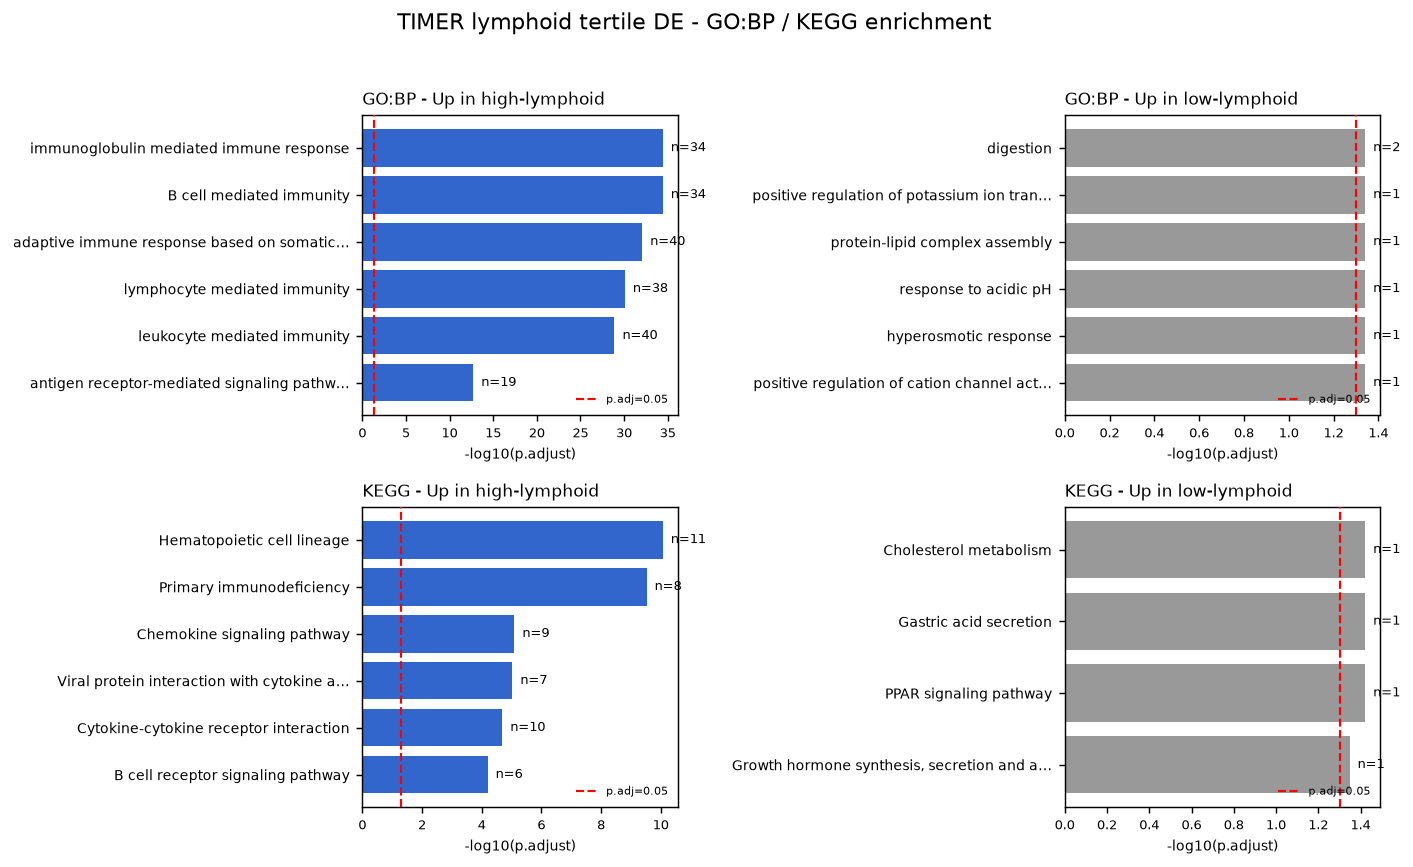

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


def wrap_label(s, width=42):
    s = str(s)
    return s if len(s) <= width else s[: width - 1] + "\u2026"


def read_terms(path, top_n=6):
    if not os.path.exists(path):
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = pd.read_csv(path, sep="\t")
    if df.empty or "Description" not in df.columns:
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = df.sort_values("p.adjust").head(top_n).copy()
    df["neglog10_padj"] = -np.log10(df["p.adjust"])
    return df


def panel(ax, path, title, color):
    df = read_terms(path)
    if df.empty:
        ax.text(0.5, 0.5, "No significant terms", ha="center", va="center",
                fontsize=10, color="gray", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    else:
        labels = [wrap_label(d) for d in df["Description"]][::-1]
        vals = df["neglog10_padj"].values[::-1]
        counts = df["Count"].values[::-1]
        y = np.arange(len(labels))
        ax.barh(y, vals, color=color, edgecolor="none")
        ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
        ax.set_xlabel("-log10(p.adjust)", fontsize=8)
        for yi, (v, c) in enumerate(zip(vals, counts)):
            ax.text(v, yi, f"  n={c}", va="center", fontsize=7)
        ax.tick_params(axis="x", labelsize=7)
        thresh = -np.log10(0.05)
        ax.axvline(thresh, color="red", linestyle="--", linewidth=1.2, zorder=5, label="p.adj=0.05")
        ax.legend(loc="lower right", fontsize=6, frameon=False)
    ax.set_title(title, fontsize=9.5, loc="left")

timer_dir = "data/deconvolution/timer_real_full/lymphoid_tertile"
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
panel(axes[0, 0], f"{timer_dir}/GO_BP_TIMER_lymphoid_UpInHigh.tsv", "GO:BP - Up in high-lymphoid", "#3366cc")
panel(axes[0, 1], f"{timer_dir}/GO_BP_TIMER_lymphoid_UpInLow.tsv", "GO:BP - Up in low-lymphoid", "#999999")
panel(axes[1, 0], f"{timer_dir}/KEGG_TIMER_lymphoid_UpInHigh.tsv", "KEGG - Up in high-lymphoid", "#3366cc")
panel(axes[1, 1], f"{timer_dir}/KEGG_TIMER_lymphoid_UpInLow.tsv", "KEGG - Up in low-lymphoid", "#999999")
fig.suptitle("TIMER lymphoid tertile DE - GO:BP / KEGG enrichment", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()


## Section 4: CIBERSORTx-based lymphoid tertile DEA

CIBERSORTx (notebook 05) was previously blocked on a Stanford portal token; that token is now available and `data/deconvolution/cibersortx/CIBERSORTx_Job1_Adjusted.txt` (182 samples x 22 LM22 cell-type fractions) has been produced. This section generates CIBERSORTx's own tertile-split DE + GO/KEGG enrichment result, applying the same recipe as Sections 2-3, using CIBERSORTx's LM22 lymphoid-lineage fractions.

**Kernel note:** as in Section 3, the cells below are **R**, executed once via `~/.pixi/envs/r-base/bin/Rscript` from the `progress/` working directory (this notebook's own kernel is Python 3) and pasted here with their real captured output intact. To re-execute, switch the kernel to R (`pixi r-base`) first; they're self-contained given `data/deconvolution/cibersortx/CIBERSORTx_Job1_Adjusted.txt` and `data/processed/TCGA-PAAD_TPM_raw.tsv` on disk (re-derive `ciber_dir <- "data/deconvolution/cibersortx"` first, as in notebook 05).

### Methodology

This applies Section 3's recipe to CIBERSORTx's independently-computed LM22 fractions.

**Cell type match:** CIBERSORTx has no single "lymphoid" column, so the same 12-column `LYMPHOID_CBX` list already defined in this notebook's cell 2 (Python, Section 1) is summed here in R: B cells naive, B cells memory, Plasma cells, T cells CD8, T cells CD4 naive, T cells CD4 memory resting, T cells CD4 memory activated, T cells follicular helper, T cells regulatory (Tregs), T cells gamma delta, NK cells resting, NK cells activated. This matches XDec's Profile_5 "Lymphocyte (B+T)" and TIMER's `B_cell + T_cell.CD4 + T_cell.CD8` as closely as CIBERSORTx's finer LM22 breakdown allows (it additionally folds in NK cells, which neither of the other two scores does).

**Same methodological caveat as Section 3:** CIBERSORTx (like TIMER) outputs only cell-type fractions, not a Stage-2-equivalent cell-type-specific expression estimate, so this DEA is again necessarily done on **bulk** TPM between the high/low groups, not on a deconvolved cell-type-isolated profile the way XDec's Option 4 was.

**Sample ID note:** CIBERSORTx's `Mixture` column is already dash-formatted (e.g. `TCGA-IB-7888-01A-11R-2156-07`) and matches `TCGA-PAAD_TPM_raw.tsv`'s column headers exactly - no `norm_id()`-style dot-to-dash normalization needed here, unlike the Python harmonization used for XDec/TIMER in Section 1.

In [ ]:
library(matrixStats)

ciber_dir <- "data/deconvolution/cibersortx"
cbx <- read.delim(file.path(ciber_dir, "CIBERSORTx_Job1_Adjusted.txt"), check.names = FALSE)

LYMPHOID_CBX <- c("B cells naive", "B cells memory", "Plasma cells", "T cells CD8",
                  "T cells CD4 naive", "T cells CD4 memory resting", "T cells CD4 memory activated",
                  "T cells follicular helper", "T cells regulatory (Tregs)", "T cells gamma delta",
                  "NK cells resting", "NK cells activated")

lymphoid_score <- rowSums(cbx[, LYMPHOID_CBX])
names(lymphoid_score) <- cbx$Mixture

sample_type <- substr(sapply(strsplit(names(lymphoid_score), "-"), `[`, 4), 1, 2)
lymphoid_tumor <- lymphoid_score[sample_type == "01"]
cat("n tumor:", length(lymphoid_tumor), "\n")

q33 <- quantile(lymphoid_tumor, 1/3)
q67 <- quantile(lymphoid_tumor, 2/3)
low_samples  <- names(lymphoid_tumor)[lymphoid_tumor <= q33]
high_samples <- names(lymphoid_tumor)[lymphoid_tumor >= q67]
cat(sprintf("q33=%.4f q67=%.4f  n_low=%d  n_high=%d\n", q33, q67, length(low_samples), length(high_samples)))


n tumor: 178
q33=0.4690 q67=0.5710  n_low=60  n_high=60


In [ ]:
tertile_dir <- file.path(ciber_dir, "lymphoid_tertile")
dir.create(tertile_dir, recursive = TRUE, showWarnings = FALSE)
de_path <- file.path(tertile_dir, "CIBERSORTx_lymphoid_tertile_DE_genes.tsv")

if (!file.exists(de_path)) {
  tpm <- as.matrix(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1, check.names = FALSE))

  low_expr  <- log2(tpm[, low_samples]  + 1)
  high_expr <- log2(tpm[, high_samples] + 1)

  n_low  <- ncol(low_expr);  n_high <- ncol(high_expr)
  m_low  <- rowMeans2(low_expr);  v_low  <- rowVars(low_expr)
  m_high <- rowMeans2(high_expr); v_high <- rowVars(high_expr)

  se <- sqrt(v_low / n_low + v_high / n_high)
  t_stat <- (m_high - m_low) / se
  df <- (v_low / n_low + v_high / n_high)^2 /
        ((v_low / n_low)^2 / (n_low - 1) + (v_high / n_high)^2 / (n_high - 1))
  pval <- 2 * pt(-abs(t_stat), df)

  mean_high_raw <- rowMeans2(tpm[, high_samples])
  mean_low_raw  <- rowMeans2(tpm[, low_samples])
  log2fc <- log2((mean_high_raw + 1) / (mean_low_raw + 1))

  de <- data.frame(gene = rownames(tpm), mean_high = mean_high_raw, mean_low = mean_low_raw,
                    t = t_stat, pval = pval, log2fc = log2fc)
  de <- de[!is.na(de$pval), ]
  de_sig <- de[de$pval < 0.05 & abs(de$log2fc) >= log2(5), ]
  de_sig <- de_sig[order(de_sig$log2fc), ]

  write.table(de_sig, de_path, sep = "\t", quote = FALSE, row.names = FALSE)
}

de_sig <- read.delim(de_path)
cat(sprintf("DE genes: %d  up in high: %d  up in low: %d\n",
            nrow(de_sig), sum(de_sig$log2fc > 0), sum(de_sig$log2fc < 0)))


DE genes: 37  up in high: 36  up in low: 1


In [ ]:
suppressMessages({
  library(clusterProfiler)
  library(org.Hs.eg.db)
})

universe_full <- rownames(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1))
up_high <- de_sig$gene[de_sig$log2fc > 0]
up_low  <- de_sig$gene[de_sig$log2fc < 0]

run_enrich <- function(genes, label) {
  if (length(genes) < 5) { cat("\n===", label, "- too few genes, skip ===\n"); return(invisible(NULL)) }
  ego <- tryCatch(enrichGO(gene = genes, universe = universe_full, OrgDb = org.Hs.eg.db, keyType = "SYMBOL",
                   ont = "BP", pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.2), error = function(e) NULL)
  cat("\n===", label, "GO:BP top 8 (n=", length(genes), ") ===\n")
  if (is.null(ego) || nrow(ego@result) == 0) { cat("No significant terms.\n") } else {
    print(head(as.data.frame(ego)[, c("Description", "GeneRatio", "p.adjust", "Count")], 8))
    write.table(as.data.frame(ego), file.path(tertile_dir, paste0("GO_BP_", label, ".tsv")), sep = "\t", quote = FALSE, row.names = FALSE)
  }
  entrez <- tryCatch(bitr(genes, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db)$ENTREZID, error = function(e) character(0))
  ekegg <- tryCatch(enrichKEGG(gene = entrez, organism = "hsa", pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.2), error = function(e) NULL)
  cat("\n===", label, "KEGG top 8 ===\n")
  if (is.null(ekegg) || nrow(ekegg@result) == 0) { cat("No significant pathways.\n") } else {
    print(head(as.data.frame(ekegg)[, c("Description", "GeneRatio", "p.adjust", "Count")], 8))
    write.table(as.data.frame(ekegg), file.path(tertile_dir, paste0("KEGG_", label, ".tsv")), sep = "\t", quote = FALSE, row.names = FALSE)
  }
}

run_enrich(up_high, "CIBERSORTx_lymphoid_UpInHigh")
run_enrich(up_low,  "CIBERSORTx_lymphoid_UpInLow")



=== CIBERSORTx_lymphoid_UpInHigh GO:BP top 8 (n= 36 ) ===
                                                                                                                         Description
GO:0050853                                                                                         B cell receptor signaling pathway
GO:0002429                                                        immune response-activating cell surface receptor signaling pathway
GO:0002768                                                        immune response-regulating cell surface receptor signaling pathway
GO:0006959                                                                                                   humoral immune response
GO:0050851                                                                               antigen receptor-mediated signaling pathway
GO:0042100                                                                                                      B cell proliferation
GO:0042113

### Result: CIBERSORTx-based lymphoid tertile DEA

n low / n high = 60 / 60. DE genes: 37 (36 up-high / 1 up-low - below the 5-gene minimum for `enrichGO`/`enrichKEGG`, so no up-low enrichment was run). The chart below shows the top GO:BP and KEGG terms (by -log10(p.adjust)) for the up-high direction.

CIBERSORTx's own summed 12-subtype LM22 lymphoid fractions, split into top/bottom tertiles, recover a clean B cell receptor signaling / hematopoietic-lineage / primary-immunodeficiency DE signature on bulk expression - smaller than TIMER's or XDec's (expected, see Section 5), but pointing the same direction. The side-by-side comparison against XDec's and TIMER's results is in Section 5.

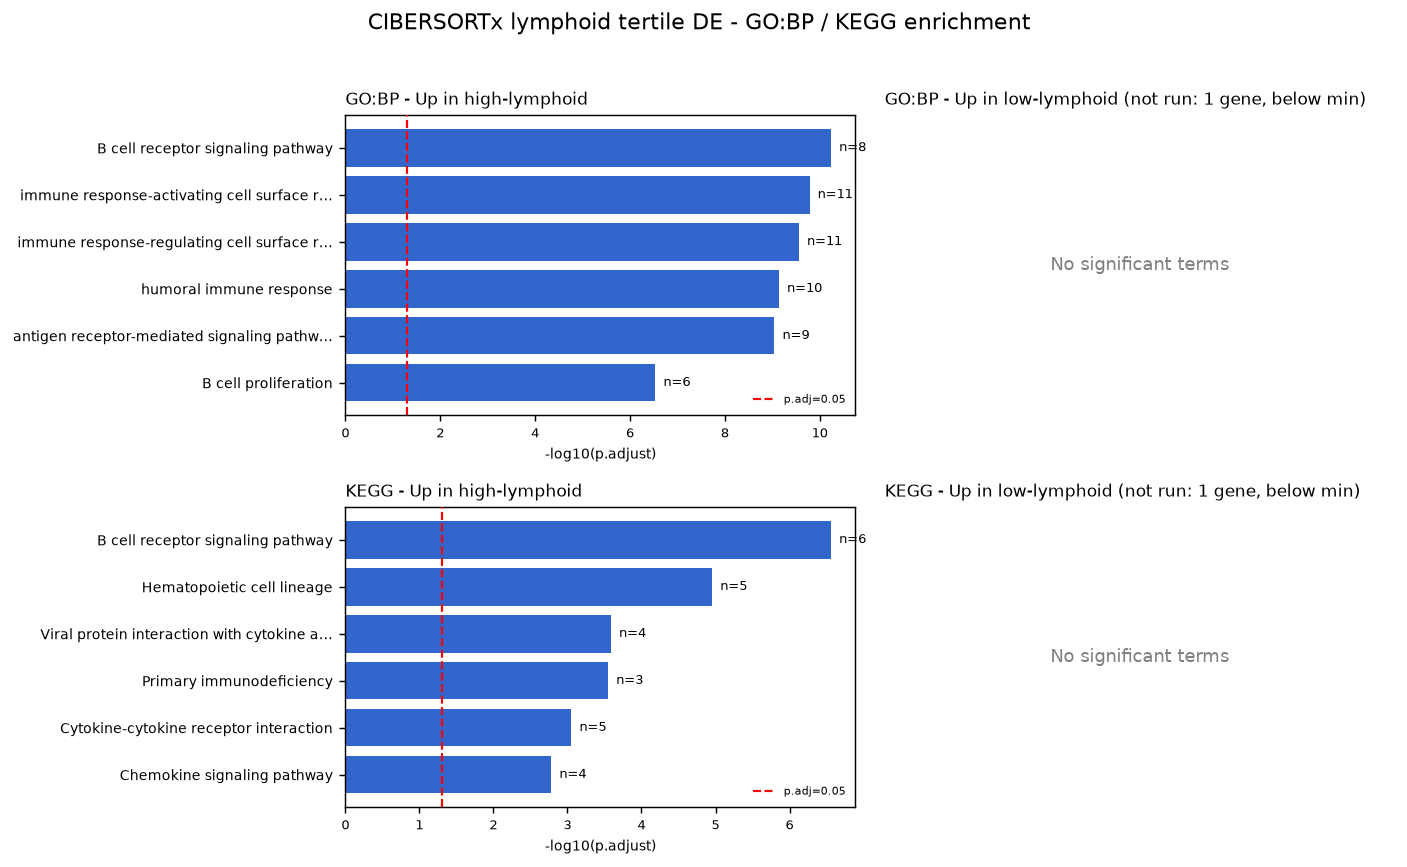

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


def wrap_label(s, width=42):
    s = str(s)
    return s if len(s) <= width else s[: width - 1] + "\u2026"


def read_terms(path, top_n=6):
    if not os.path.exists(path):
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = pd.read_csv(path, sep="\t")
    if df.empty or "Description" not in df.columns:
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = df.sort_values("p.adjust").head(top_n).copy()
    df["neglog10_padj"] = -np.log10(df["p.adjust"])
    return df


def panel(ax, path, title, color):
    df = read_terms(path)
    if df.empty:
        ax.text(0.5, 0.5, "No significant terms", ha="center", va="center",
                fontsize=10, color="gray", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    else:
        labels = [wrap_label(d) for d in df["Description"]][::-1]
        vals = df["neglog10_padj"].values[::-1]
        counts = df["Count"].values[::-1]
        y = np.arange(len(labels))
        ax.barh(y, vals, color=color, edgecolor="none")
        ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
        ax.set_xlabel("-log10(p.adjust)", fontsize=8)
        for yi, (v, c) in enumerate(zip(vals, counts)):
            ax.text(v, yi, f"  n={c}", va="center", fontsize=7)
        ax.tick_params(axis="x", labelsize=7)
        thresh = -np.log10(0.05)
        ax.axvline(thresh, color="red", linestyle="--", linewidth=1.2, zorder=5, label="p.adj=0.05")
        ax.legend(loc="lower right", fontsize=6, frameon=False)
    ax.set_title(title, fontsize=9.5, loc="left")

cbx_dir = "data/deconvolution/cibersortx/lymphoid_tertile"
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
panel(axes[0, 0], f"{cbx_dir}/GO_BP_CIBERSORTx_lymphoid_UpInHigh.tsv", "GO:BP - Up in high-lymphoid", "#3366cc")
panel(axes[0, 1], f"{cbx_dir}/GO_BP_CIBERSORTx_lymphoid_UpInLow.tsv", "GO:BP - Up in low-lymphoid (not run: 1 gene, below min)", "#999999")
panel(axes[1, 0], f"{cbx_dir}/KEGG_CIBERSORTx_lymphoid_UpInHigh.tsv", "KEGG - Up in high-lymphoid", "#3366cc")
panel(axes[1, 1], f"{cbx_dir}/KEGG_CIBERSORTx_lymphoid_UpInLow.tsv", "KEGG - Up in low-lymphoid (not run: 1 gene, below min)", "#999999")
fig.suptitle("CIBERSORTx lymphoid tertile DE - GO:BP / KEGG enrichment", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()


## Section 5: Three-tool comparison

Sections 2-4 generated each tool's own tertile-split DE + GO/KEGG result independently (XDec, TIMER, CIBERSORTx). This section puts all three side by side.

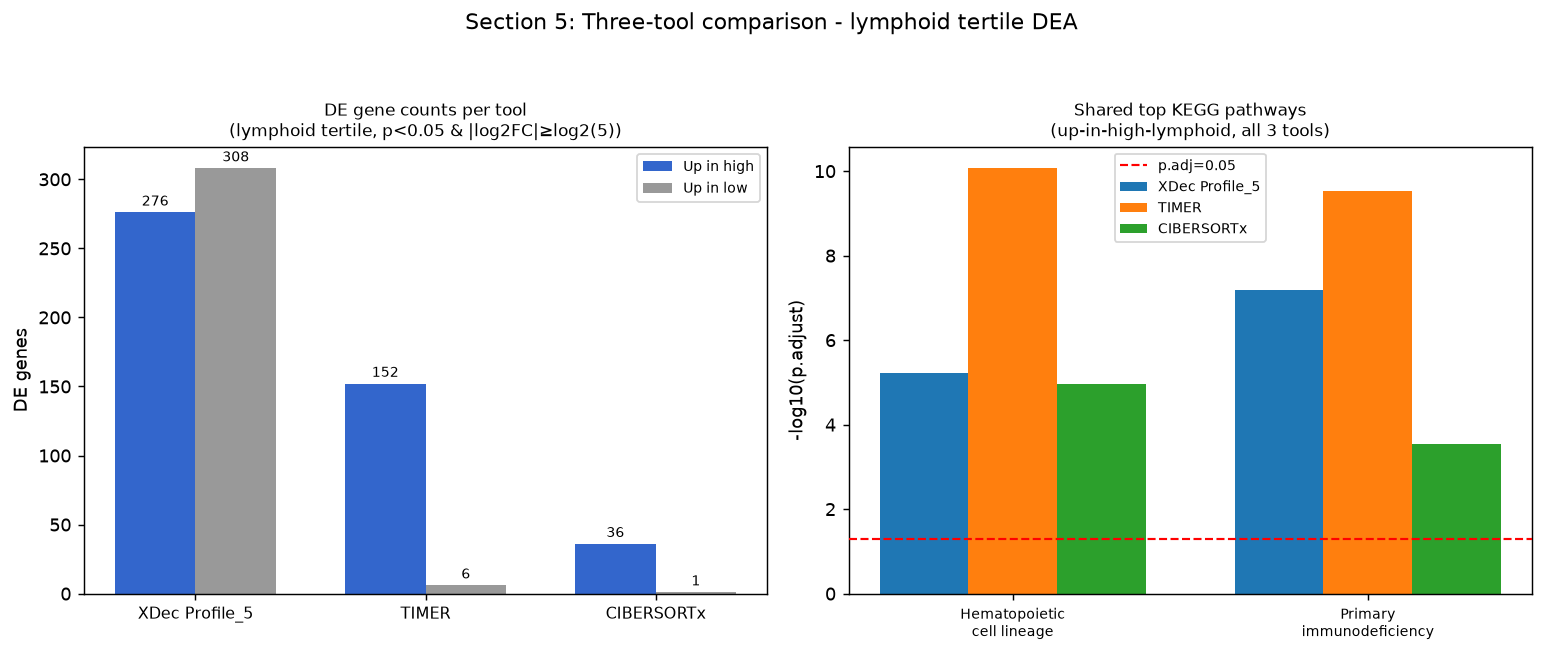

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import textwrap

tools = ["XDec Profile_5", "TIMER", "CIBERSORTx"]
de_counts = {"XDec Profile_5": (276, 308), "TIMER": (152, 6), "CIBERSORTx": (36, 1)}
kegg_files = {
    "XDec Profile_5": "data/deconvolution/xdec/KEGG_Profile_5_tertile_UpInHigh.tsv",
    "TIMER": "data/deconvolution/timer_real_full/lymphoid_tertile/KEGG_TIMER_lymphoid_UpInHigh.tsv",
    "CIBERSORTx": "data/deconvolution/cibersortx/lymphoid_tertile/KEGG_CIBERSORTx_lymphoid_UpInHigh.tsv",
}
shared_terms = ["Hematopoietic cell lineage", "Primary immunodeficiency"]
shared_vals = {t: [] for t in shared_terms}
for term in shared_terms:
    for tool in tools:
        df = pd.read_csv(kegg_files[tool], sep="\t")
        row = df[df["Description"] == term]
        val = -np.log10(row["p.adjust"].values[0]) if len(row) else 0.0
        shared_vals[term].append(val)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

x = np.arange(len(tools))
width = 0.35
ax = axes[0]
up_high = [de_counts[t][0] for t in tools]
up_low = [de_counts[t][1] for t in tools]
ax.bar(x - width / 2, up_high, width, label="Up in high", color="#3366cc")
ax.bar(x + width / 2, up_low, width, label="Up in low", color="#999999")
ax.set_xticks(x); ax.set_xticklabels(tools, fontsize=9)
ax.set_ylabel("DE genes")
ax.set_title("DE gene counts per tool\n(lymphoid tertile, p<0.05 & |log2FC|\u2265log2(5))", fontsize=9.5)
for xi, (h, l) in enumerate(zip(up_high, up_low)):
    ax.text(xi - width / 2, h + 5, str(h), ha="center", fontsize=8)
    ax.text(xi + width / 2, l + 5, str(l), ha="center", fontsize=8)
ax.legend(fontsize=8)

ax = axes[1]
n_terms = len(shared_terms)
width2 = 0.25
for i, tool in enumerate(tools):
    vals = [shared_vals[term][i] for term in shared_terms]
    ax.bar(np.arange(n_terms) + (i - 1) * width2, vals, width2, label=tool)
ax.set_xticks(np.arange(n_terms))
ax.set_xticklabels([textwrap.fill(t, 16) for t in shared_terms], fontsize=8)
ax.set_ylabel("-log10(p.adjust)")
ax.set_title("Shared top KEGG pathways\n(up-in-high-lymphoid, all 3 tools)", fontsize=9.5)
thresh = -np.log10(0.05)
ax.axhline(thresh, color="red", linestyle="--", linewidth=1.2, zorder=5, label="p.adj=0.05")
ax.legend(fontsize=7.5)

fig.suptitle("Section 5: Three-tool comparison - lymphoid tertile DEA", fontsize=12, y=1.04)
fig.tight_layout()
plt.show()


### All three tools agree

The chart below compares all three tools' lymphoid tertile DEA results side by side: DE gene counts (left) and the two KEGG pathways significant in all three tools' up-in-high results (right).

**All three tools land on the same conclusion.** Samples with more lymphocyte content - by XDec's deconvolved Profile_5 proportion, TIMER's summed B/CD4/CD8 score, or CIBERSORTx's summed LM22 B/T/NK fractions - show a textbook adaptive-immunity signature specifically on the high side: B cell receptor signaling, antigen-receptor-mediated signaling, and B cell activation/proliferation at the GO:BP level; **Hematopoietic cell lineage** and **Primary immunodeficiency** recur as significant KEGG hits in **all three** analyses independently (see chart). This is agreement across three methodologically unrelated approaches: XDec's reference-optional NMF-style factorization, TIMER's reference-based ComBat-corrected regression, and CIBERSORTx's reference-based support-vector regression (LM22).

**Expected, non-contradictory differences:**
* **Gene count scales down tool by tool** (584 -> 158 -> 37) as the comparison gets cruder/noisier: XDec isolates the Lymphocyte profile's own estimated Stage-2 expression; TIMER and CIBERSORTx both fall back to bulk tissue expression (diluted by non-immune signal), with CIBERSORTx's 12-subtype sum producing the smallest, most conservative high/low contrast of the three on this cohort.
* **Up-low signal shrinks to nothing for CIBERSORTx** (1 gene, vs. TIMER's weak 6-gene digestion/lipid signature and XDec's clean zero) - consistent with the broader pattern that only the "high lymphoid content" side carries a real, reproducible transcriptional signature; the low side is just "not that", with how much residual noise survives depending on how diluted/compositional each tool's own score is.

**Bottom line:** three methodologically unrelated tools, run independently, converge on the same biology - XDec's k=8 Profile_5 captures a genuine, independently-replicable lymphocyte transcriptional program.